# Cyclistic Bike Share Analysis

## Notebook 4 - Exploratory Data Analysis (EDA)

Objective:
- Explore the cleaned dataset to identify patterns, trends and behavioural differences between annual members and casual riders, providing evidence to answer the business question.

Business Question:
- How do annual members and casual riders use Cyclistic bikes differently?

Input: 00_Data/02_Processed/cyclistic_202506_202605_featured.parquet

Output: Business Insight Report

### Import Libraries and Dataset

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

df = pd.read_parquet(
    "../00_Data/02_Processed/cyclistic_202506_202605_featured.parquet"
)

### 1. Dataset Overview

In [2]:
# Validating dataset

df.shape

(5842803, 22)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5842803 entries, 0 to 5842802
Data columns (total 22 columns):
 #   Column              Dtype          
---  ------              -----          
 0   ride_id             object         
 1   rideable_type       object         
 2   started_at          datetime64[ns] 
 3   ended_at            datetime64[ns] 
 4   start_station_name  object         
 5   start_station_id    object         
 6   end_station_name    object         
 7   end_station_id      object         
 8   start_lat           float64        
 9   start_lng           float64        
 10  end_lat             float64        
 11  end_lng             float64        
 12  member_casual       object         
 13  ride_duration       timedelta64[ns]
 14  ride_duration_min   float64        
 15  ride_date           object         
 16  ride_month          category       
 17  ride_month_num      int32          
 18  day_of_week         category       
 19  start_hour          i

### 2. Overall Usage

Question:
- How does the overall usage vary between rider groups?

Finding:
- In the analysis period, members account for 64.14% (3,747,364 rides) of total rides, while casual riders account for the remaining 35.86% (2,095,439 rides).

In [4]:
# Study overall usage - number of rides and share

df["member_casual"].value_counts()

member_casual
member    3747364
casual    2095439
Name: count, dtype: int64

In [5]:
df["member_casual"].value_counts(normalize=True)

member_casual
member    0.641364
casual    0.358636
Name: proportion, dtype: float64

### 3. Ride Duration

Question:
- How does the ride duration vary between rider groups?

Key Findings:
- The average trip duration of casual riders (18.9 minutes) is approximately 56.47% longer than that of members (12.1 minutes).
- The median trip duration of casual riders (11.2 minutes) is approximately 30% longer than that of members (8.6 minutes).
- Both rider groups show right-skewed ride duration distributions, with the highest concentration of trips under 20 minutes.
- Members most frequently take trips between 5–10 minutes, whereas casual riders peak between 10–20 minutes.
- Approximately 80% of member trips last less than 16.6 minutes, compared with 24.3 minutes for casual riders.

Insight:
- Casual riders generally take longer trips, suggesting that their riding behaviour differs substantially from that of annual members.

In [6]:
# 3.1 member vs casual ride duration overview

df.groupby("member_casual")["ride_duration_min"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
member_casual,,,,,,,,
casual,2095439.0,18.87,38.27,0.0,6.22,11.24,20.77,1439.98
member,3747364.0,12.06,21.65,0.0,5.03,8.59,14.58,1439.90


Text(0, 0.5, 'Number of Rides')

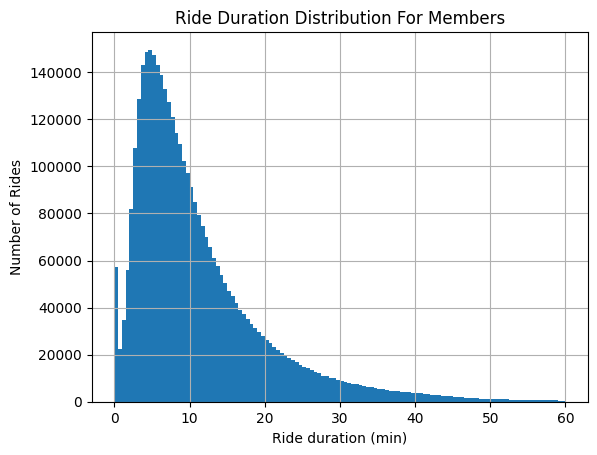

In [7]:
# 3.2 Distribution

member = df[df["member_casual"] == "member"]
casual = df[df["member_casual"] == "casual"]

# Understanding the ride duration distribution by plotting a histogram

member[member["ride_duration_min"] <= 60]["ride_duration_min"].hist(
    bins=120,
)

plt.title("Ride Duration Distribution For Members")
plt.xlabel("Ride duration (min)")
plt.ylabel("Number of Rides")

Text(0, 0.5, 'Number of Rides')

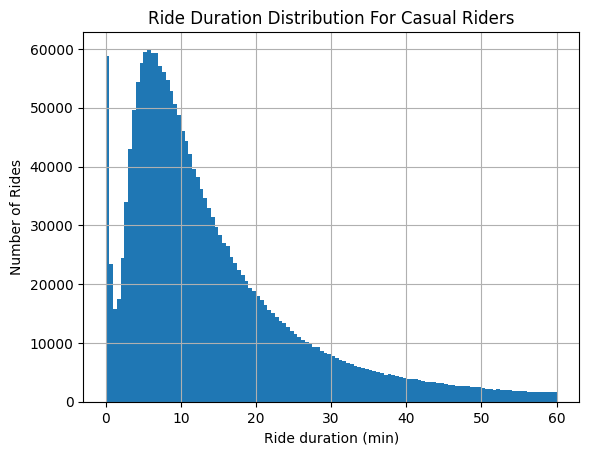

In [8]:
# Understanding the ride duration distribution by plotting a histogram

casual[casual["ride_duration_min"] <= 60]["ride_duration_min"].hist(
    bins=120
)

plt.title("Ride Duration Distribution For Casual Riders")
plt.xlabel("Ride duration (min)")
plt.ylabel("Number of Rides")

Text(0, 0.5, 'Number of Rides')

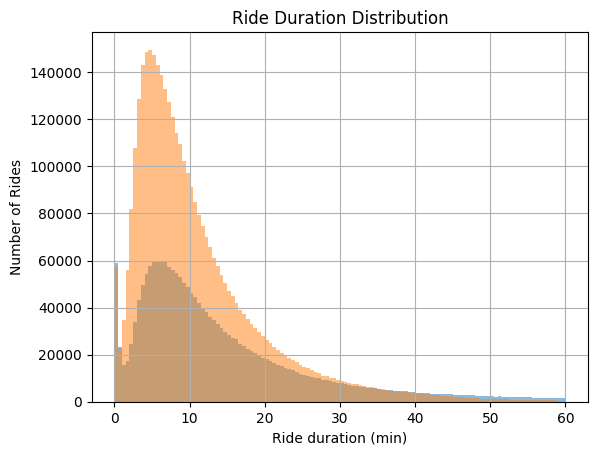

In [9]:
# Comparing two histogram side by side

df[df["ride_duration_min"] <= 60].groupby("member_casual", observed=True)["ride_duration_min"].hist(
    bins=120,
    alpha=0.5
)

plt.title("Ride Duration Distribution")
plt.xlabel("Ride duration (min)")
plt.ylabel("Number of Rides")

In [10]:
# Calculate the 80th percentile of ride duration

print(member["ride_duration_min"].quantile(0.80).round(2))
print(casual["ride_duration_min"].quantile(0.80).round(2))

16.64
24.32


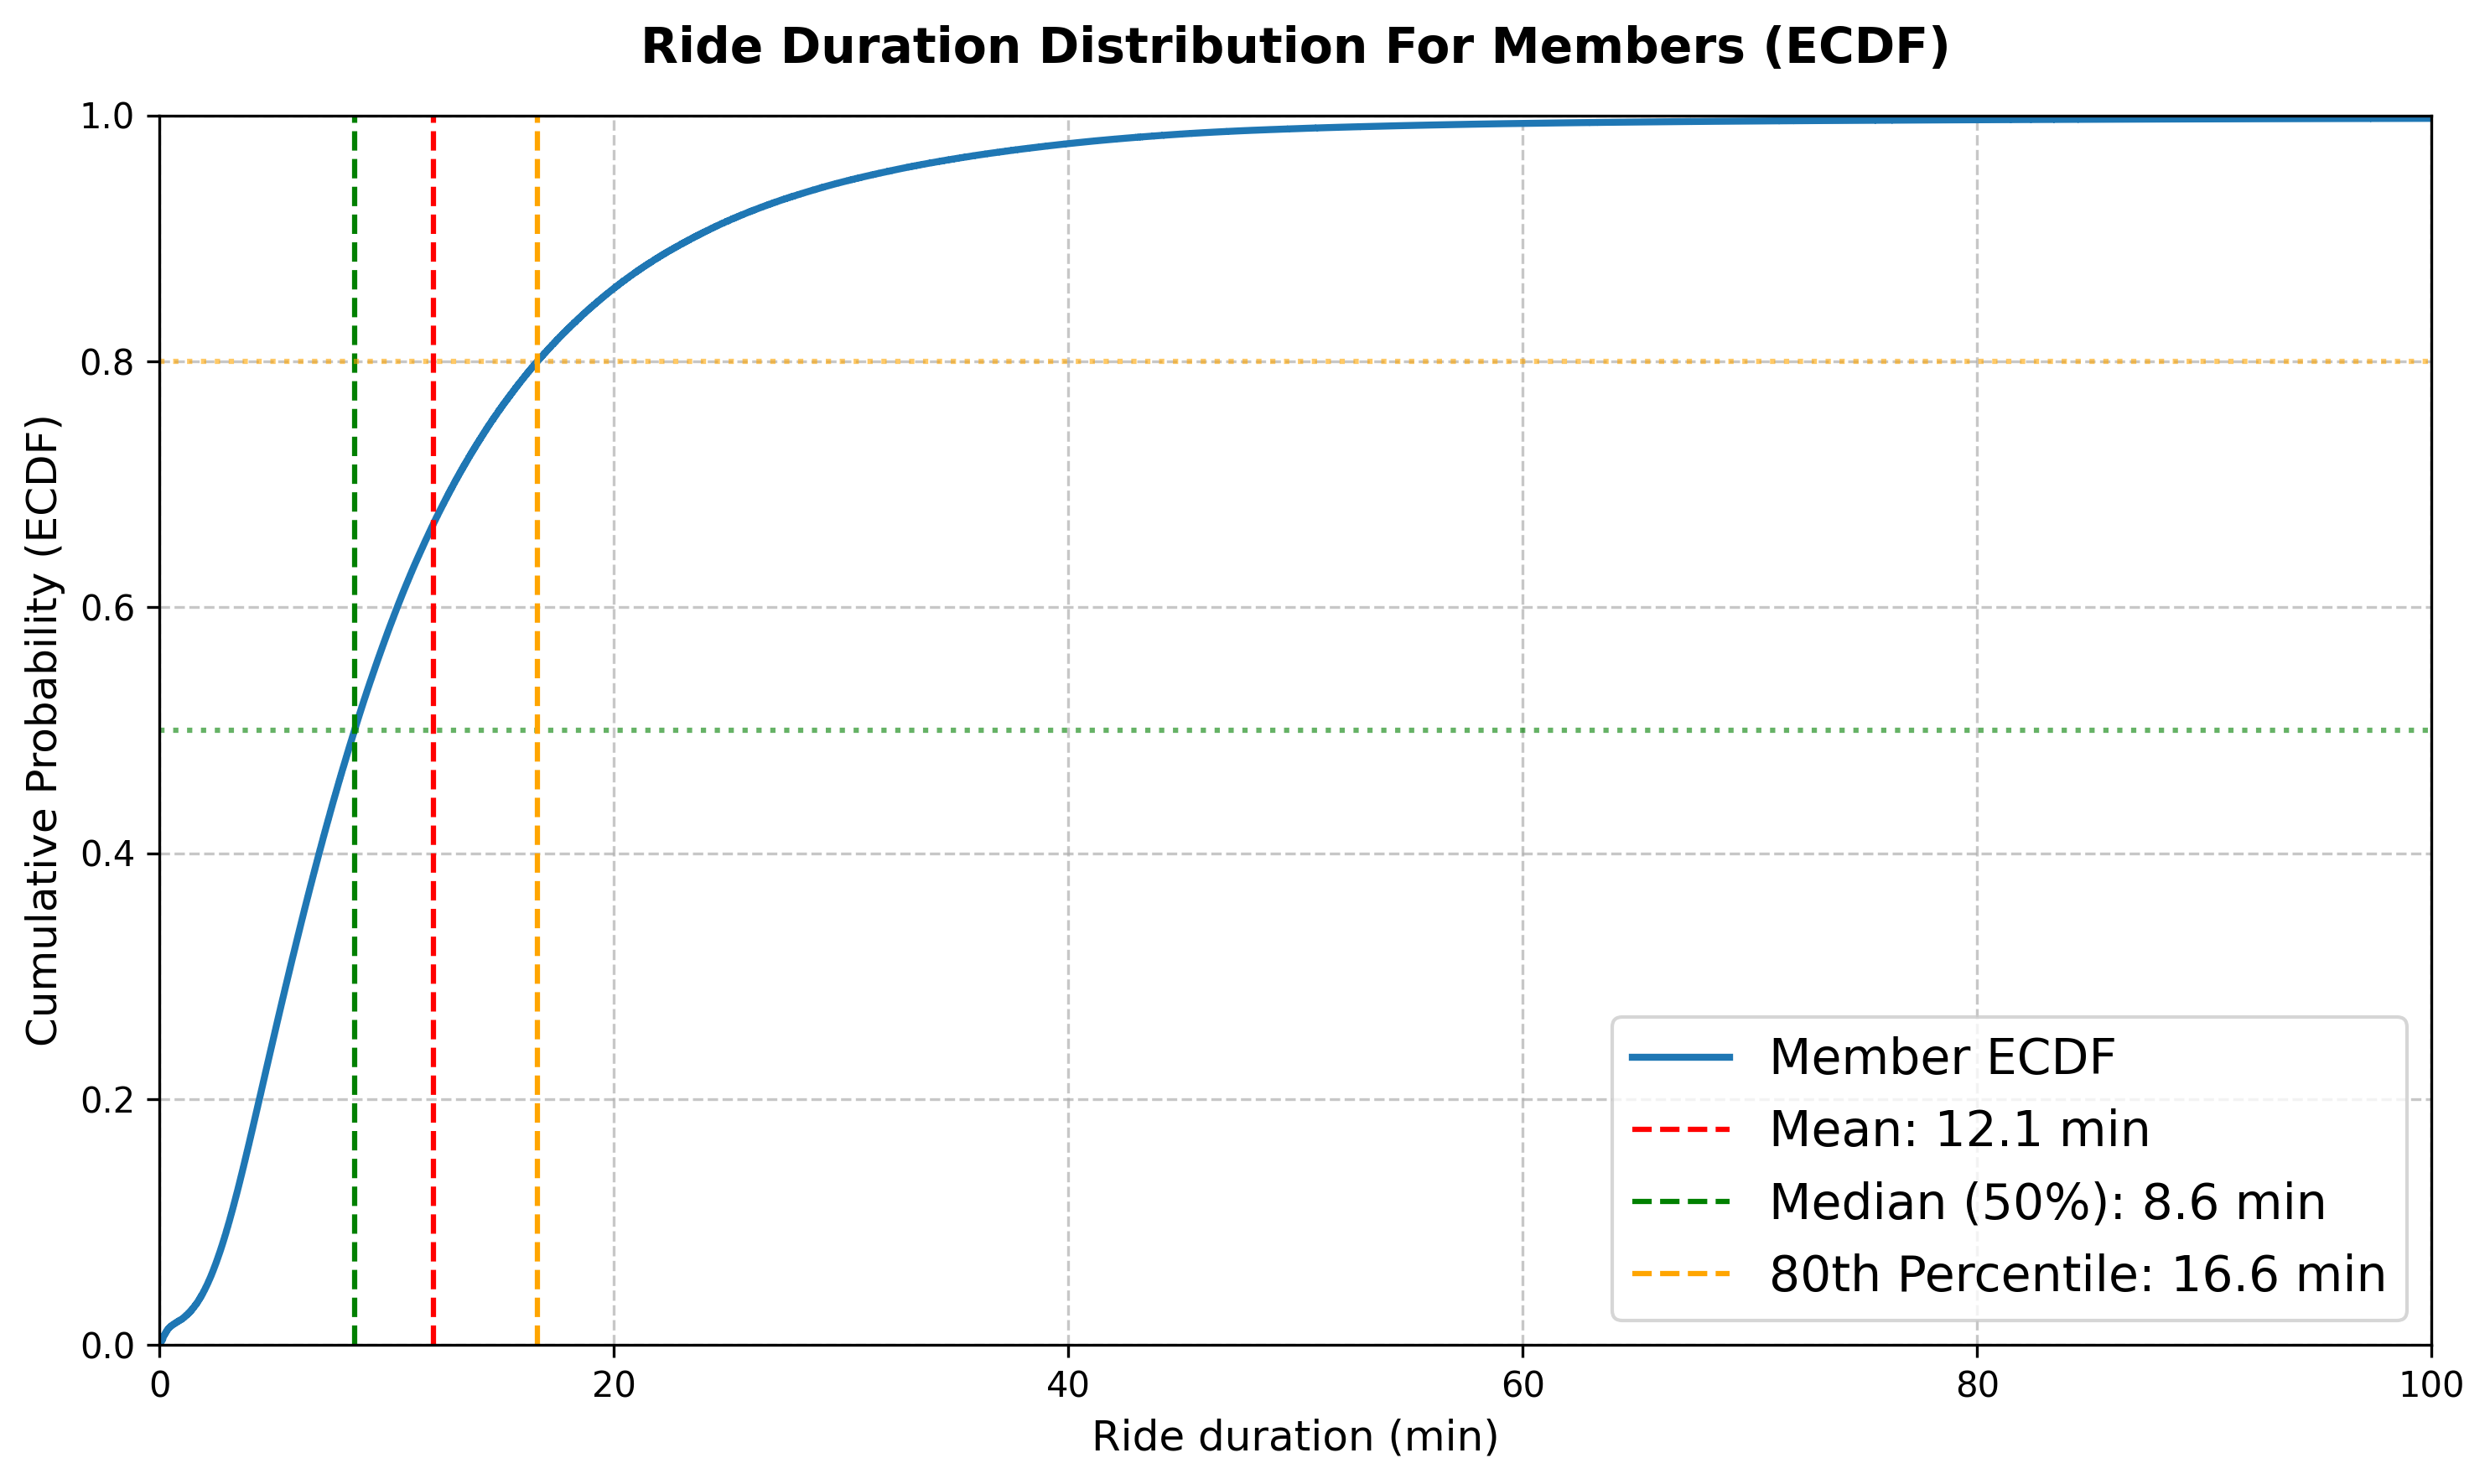

In [11]:
# Plotting ECDF for insight report

# Members
# Preparing dataset
durations_member = member["ride_duration_min"]

# Calculating stats values
mean_val = durations_member.mean()
median_val = durations_member.median()
p80_val = np.percentile(durations_member, 80)

# Plot ECDF
plt.figure(figsize=(10, 6), dpi=300)
plt.ecdf(durations_member, label="Member ECDF", color="#1f77b4", linewidth=2)

# Plot 3 important lines and labels
# Mean
plt.axvline(
    x=mean_val,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean: {mean_val:.1f} min",
)

# Median
plt.axvline(
    x=median_val,
    color="green",
    linestyle="--",
    linewidth=1.5,
    label=f"Median (50%): {median_val:.1f} min",
)
plt.axhline(y=0.50, color="green", linestyle=":", alpha=0.6)

# 80th Percentile
plt.axvline(
    x=p80_val,
    color="orange",
    linestyle="--",
    linewidth=1.5,
    label=f"80th Percentile: {p80_val:.1f} min",
)
plt.axhline(y=0.80, color="orange", linestyle=":", alpha=0.6)

# Limit x-axis to 0-100 mins
plt.xlim(0,100)

# Titles, labels
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.title("Ride Duration Distribution For Members (ECDF)", fontsize=14, pad=15, weight="bold")
plt.xlabel("Ride duration (min)", fontsize=12)
plt.ylabel("Cumulative Probability (ECDF)", fontsize=12)
plt.legend(loc="lower right", frameon=True, fontsize=14)

plt.tight_layout()
plt.show()

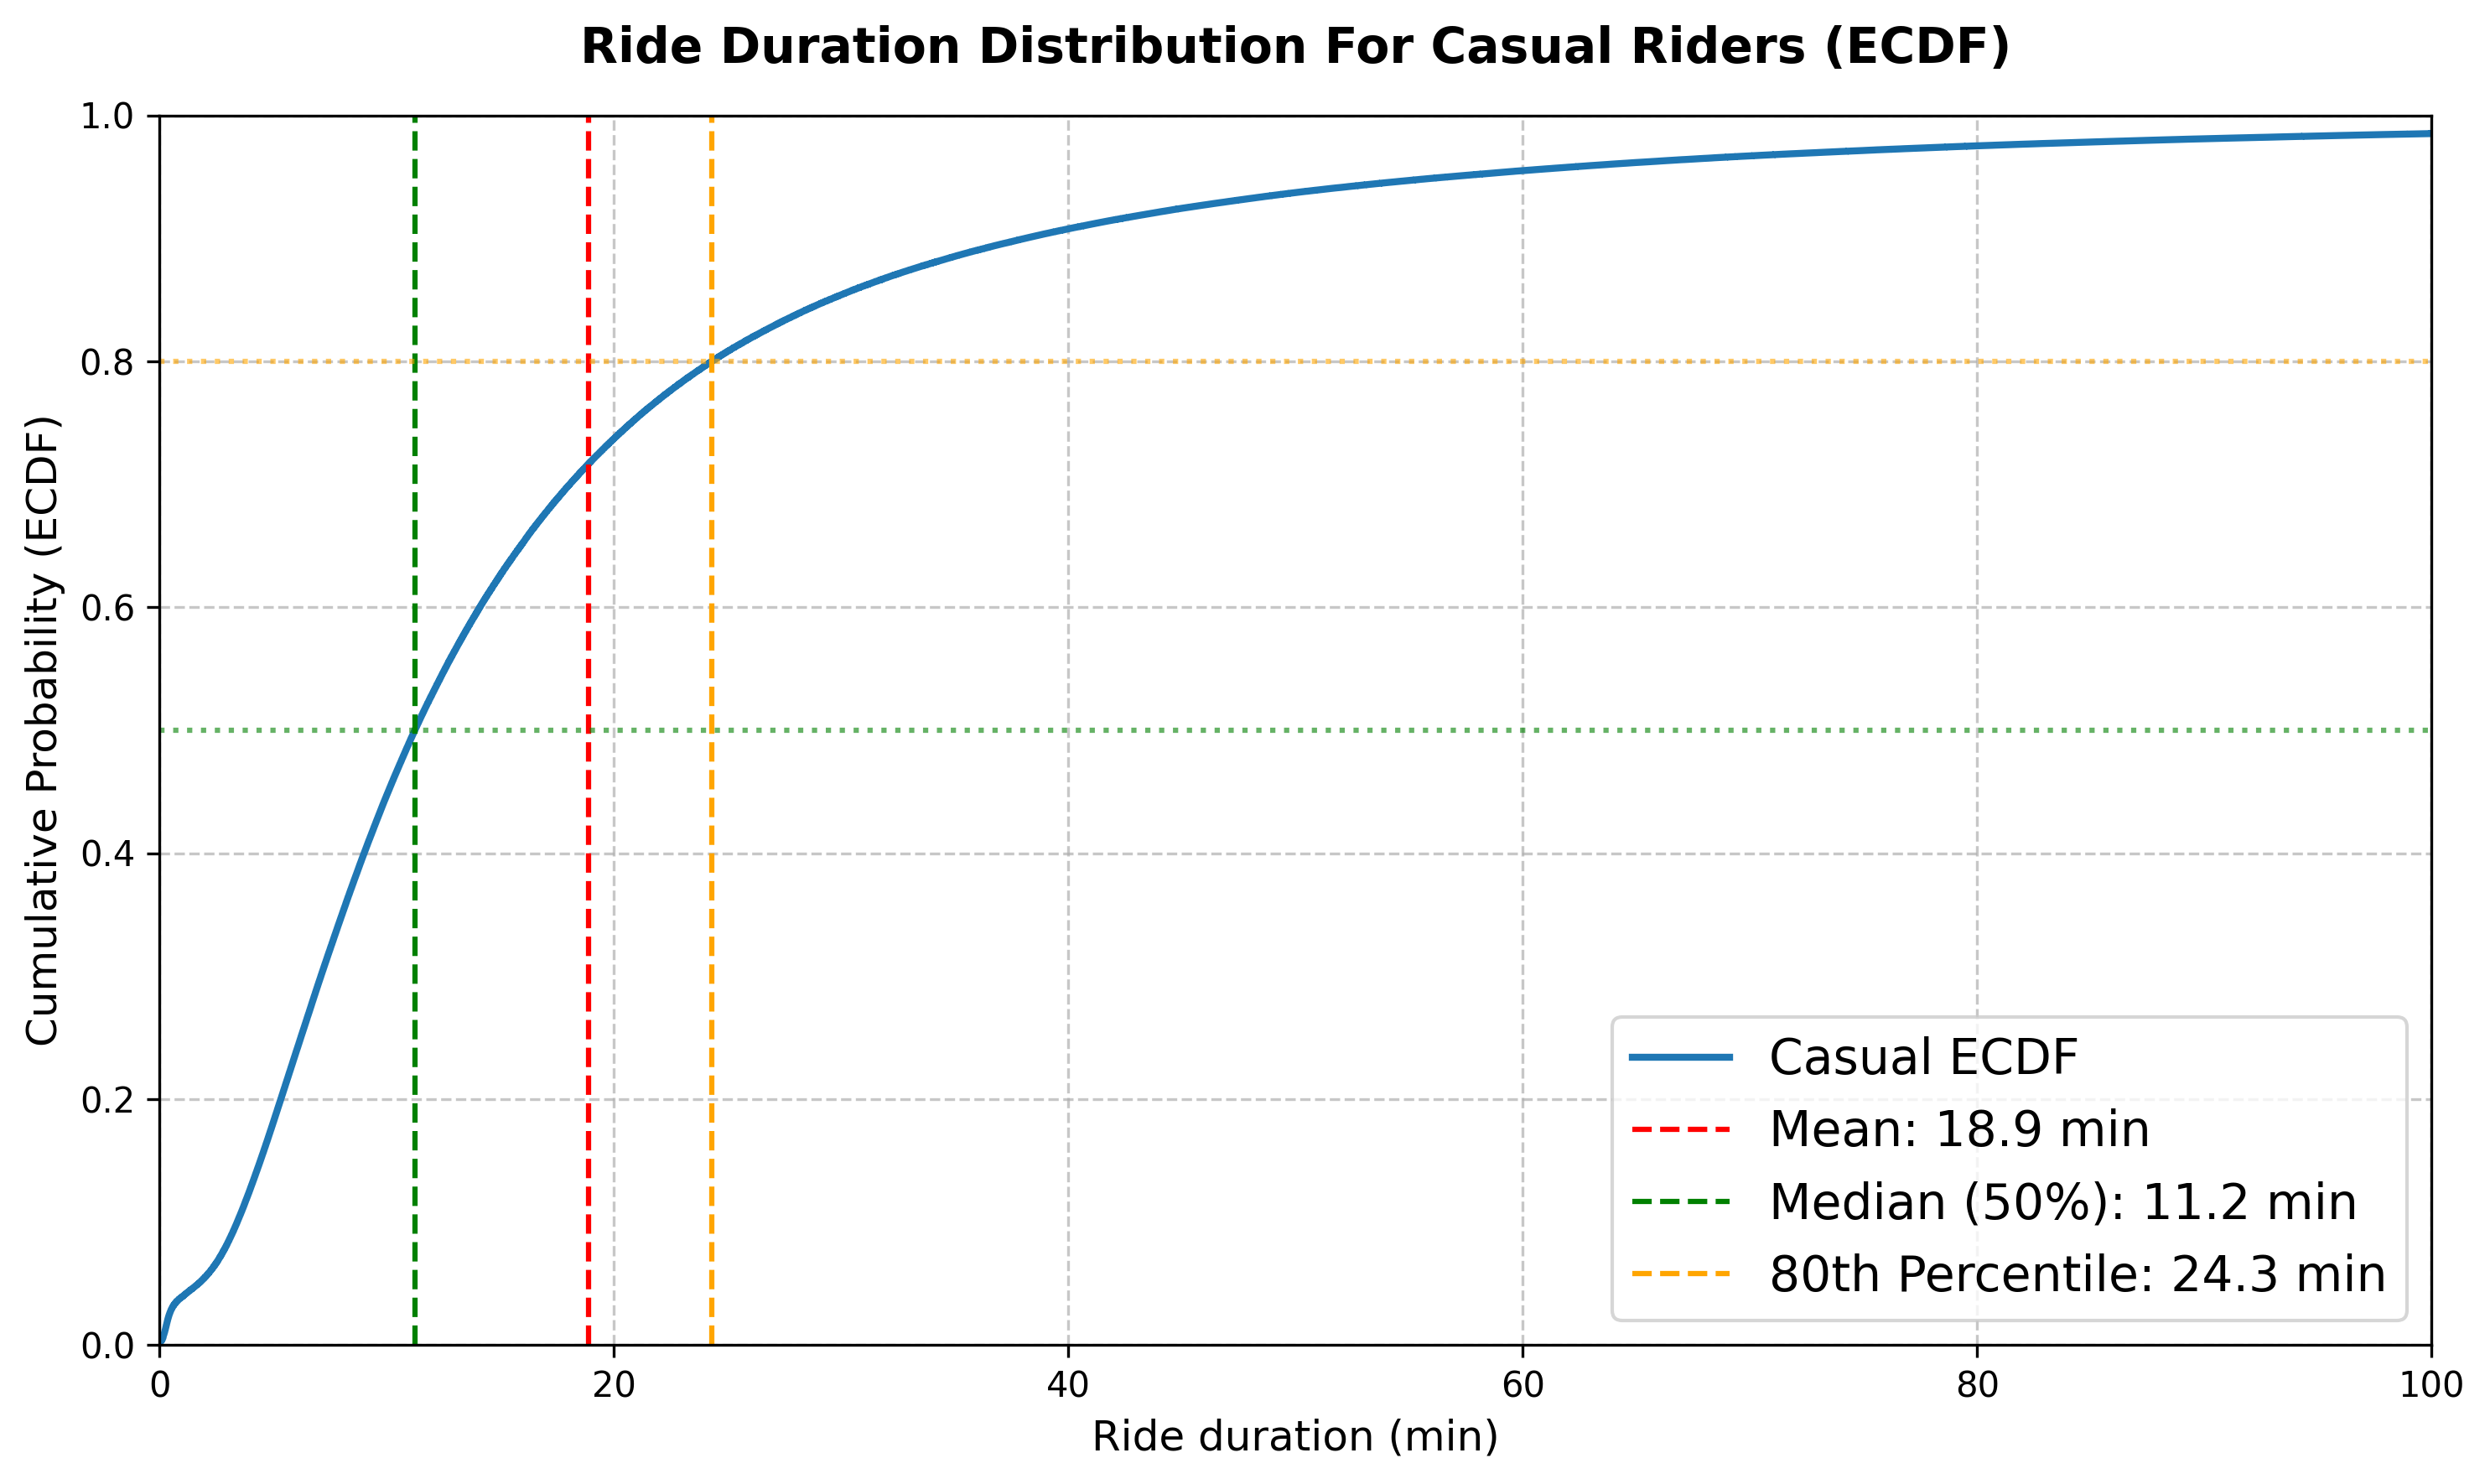

In [12]:
# Casual
# Preparing dataset
durations_casual = casual["ride_duration_min"]

# Calculating stats values
mean_val = durations_casual.mean()
median_val = durations_casual.median()
p80_val = np.percentile(durations_casual, 80)

# Plot ECDF
plt.figure(figsize=(10, 6), dpi=300)
plt.ecdf(durations_casual, label="Casual ECDF", color="#1f77b4", linewidth=2)

# Plot 3 important lines and labels
# Mean
plt.axvline(
    x=mean_val,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean: {mean_val:.1f} min",
)

# Median
plt.axvline(
    x=median_val,
    color="green",
    linestyle="--",
    linewidth=1.5,
    label=f"Median (50%): {median_val:.1f} min",
)
plt.axhline(y=0.50, color="green", linestyle=":", alpha=0.6)

# 80th Percentile
plt.axvline(
    x=p80_val,
    color="orange",
    linestyle="--",
    linewidth=1.5,
    label=f"80th Percentile: {p80_val:.1f} min",
)
plt.axhline(y=0.80, color="orange", linestyle=":", alpha=0.6)

# Limit x-axis to 0-100 mins
plt.xlim(0,100)

# Labels, title
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.title("Ride Duration Distribution For Casual Riders (ECDF)", fontsize=14, pad=15, weight="bold")
plt.xlabel("Ride duration (min)", fontsize=12)
plt.ylabel("Cumulative Probability (ECDF)", fontsize=12)
plt.legend(loc="lower right", frameon=True, fontsize=14)

plt.tight_layout()
plt.show()

In [13]:
# 3.4 Duration Group

# Define duration group based on trip duration

bins = [0, 5, 10, 20, 30, 60, 1440]

labels = [
    "<5",
    "5-10",
    "10-20",
    "20-30",
    "30-60",
    "60+"
]

df["duration_group"] = pd.cut(
    df["ride_duration_min"],
    bins=bins,
    labels=labels,
    right=False,
    include_lowest=True
)

df["duration_group"].value_counts(sort=False)

duration_group
<5       1307686
5-10     1792019
10-20    1664383
20-30     568406
30-60     391217
60+       119092
Name: count, dtype: int64

In [14]:
ct = pd.crosstab(
    df["duration_group"],
    df["member_casual"],
)

ct

member_casual,casual,member
duration_group,,
<5,378303,929383
5-10,558301,1233718
10-20,607705,1056678
20-30,245129,323277
30-60,211695,179522
60+,94306,24786


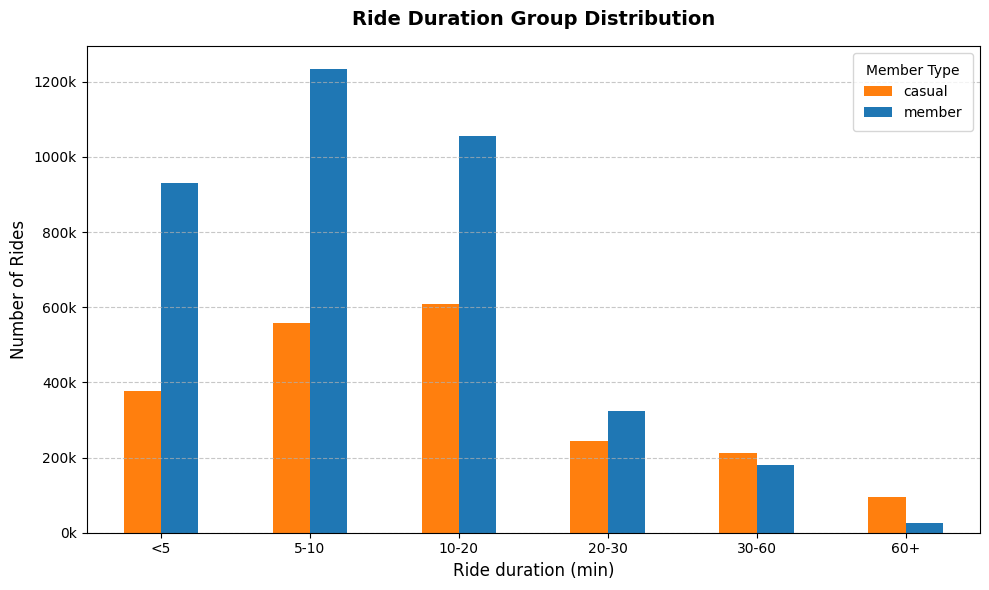

In [15]:
ax = ct.plot(kind='bar', rot=0, color=['#ff7f0e','#1f77b4'], figsize=(10,6))

ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{int(x/1000)}k')
)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.title("Ride Duration Group Distribution", fontsize=14, pad=15, weight="bold")
plt.xlabel("Ride duration (min)", fontsize=12)
plt.ylabel("Number of Rides", fontsize=12)
plt.legend(title="Member Type", fontsize=10, borderpad=0.8)

plt.tight_layout()
plt.show()

### 4. Day of Week

Question:
- How does usage vary throughout the week for both rider groups?

Key Findings:
- Trip Counts
    - Members show relatively consistent weekday riding, with only a modest reduction (approximately 20%) during weekends.
    - Casual rider activity remains stable from Monday to Thursday, before increasing significantly on Friday through Sunday, reaching its highest level on Saturday (approximately 80% higher than weekdays).
- Ride Duration
    - Members maintain a consistent average ride duration throughout the week, with only a slight increase (approximately 10%) during weekends.
    - Casual riders exhibit noticeably longer rides on weekends, with average trip durations increasing by approximately 20–30%.
    - Across all days, casual riders consistently ride 40–60% longer than members.

Insight:
- Members demonstrate a stable weekday riding pattern, whereas casual riders display a strong weekend-oriented behavior.

In [16]:
# 4.1 Trip count

dow_trip_count = (
    df.groupby(
        ["day_of_week"],
        observed=True,
    )["member_casual"]
    .value_counts(sort=False)
    .unstack()
)

dow_trip_count

member_casual,casual,member
day_of_week,,
Monday,244717,527115
Tuesday,234389,592396
Wednesday,236046,594283
Thursday,266545,601346
Friday,322632,548561
Saturday,431737,469412
Sunday,359373,414251


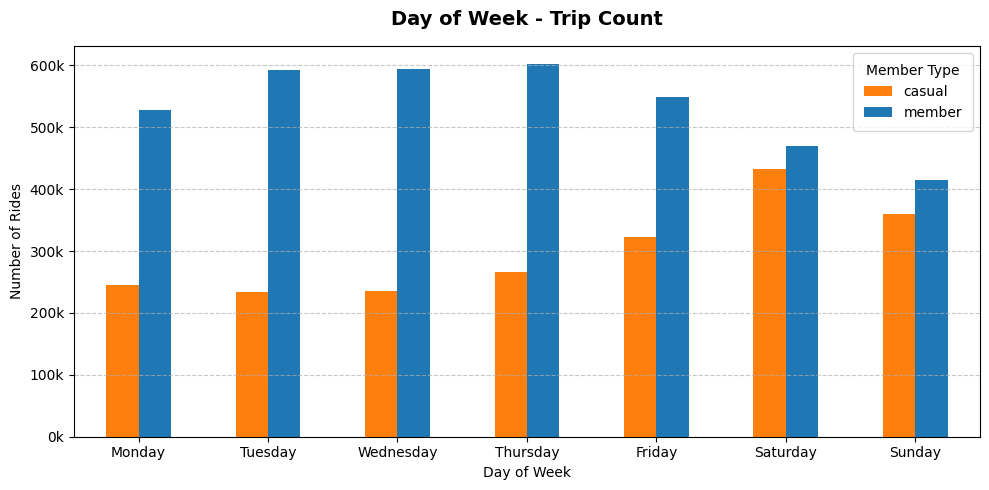

In [17]:
# Plotting bar chart

ax = dow_trip_count.plot(
    kind='bar', figsize=(10,5), rot=0, color=['#ff7f0e','#1f77b4']
)

ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{int(x/1000)}k')
)

plt.title("Day of Week - Trip Count", fontsize=14, pad=15, weight="bold")
plt.xlabel('Day of Week')
plt.ylabel("Number of Rides")
plt.legend(title="Member Type", frameon=True, borderpad=0.8, fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

In [18]:
# 4.2 Trip duration

# Mean

dow_avg_duration = (
    df.groupby([
    "day_of_week",
    "member_casual"
    ], 
    observed=True
    )["ride_duration_min"]
    .mean()
    .unstack()
)

dow_avg_duration

member_casual,casual,member
day_of_week,,
Monday,19.004341,11.806898
Tuesday,16.468594,11.632461
Wednesday,15.676066,11.562072
Thursday,16.471431,11.606467
Friday,18.387353,11.966942
Saturday,21.198339,13.183000
Sunday,21.861257,13.227352


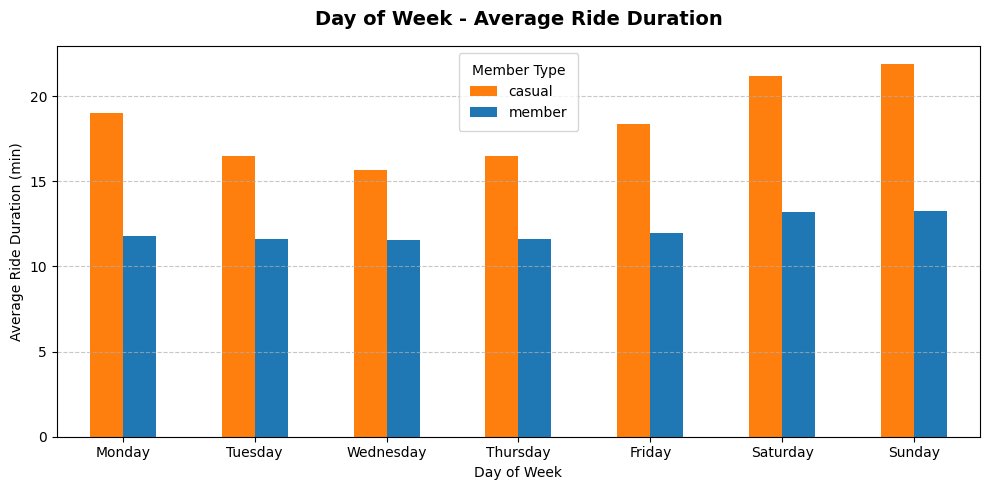

In [19]:
# Plotting avg ride duration bar chart

ax = dow_avg_duration.plot(kind='bar', figsize=(10,5), rot=0, color=['#ff7f0e','#1f77b4'])

plt.title("Day of Week - Average Ride Duration", fontsize=14, pad=15, weight="bold")
plt.xlabel("Day of Week")
plt.ylabel("Average Ride Duration (min)")
plt.legend(title="Member Type", frameon=True, borderpad=0.8, fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()

In [20]:
# Median

dow_median_duration = (
    df.groupby([
    "day_of_week",
    "member_casual",
    ],
    observed=True)["ride_duration_min"]
    .median()
    .unstack()
)

dow_median_duration

member_casual,casual,member
day_of_week,,
Monday,11.024300,8.328717
Tuesday,9.949350,8.416992
Wednesday,9.737058,8.426433
Thursday,10.018850,8.448683
Friday,10.965017,8.439333
Saturday,12.970417,9.281217
Sunday,13.070633,9.140717


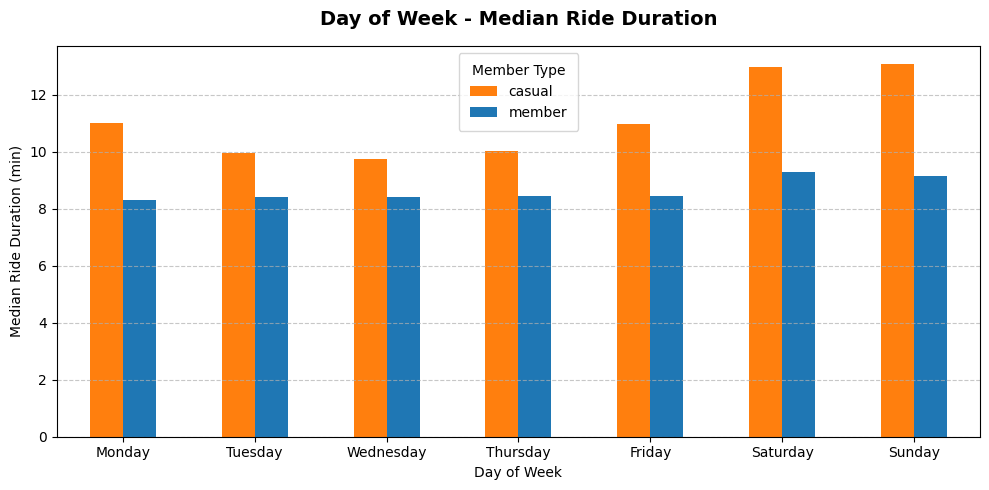

In [21]:
# Plotting median ride duration bar chart

ax = dow_median_duration.plot(kind='bar', figsize=(10,5), rot=0, color=['#ff7f0e','#1f77b4'])

plt.title("Day of Week - Median Ride Duration", fontsize=14, pad=15, weight="bold")
plt.xlabel("Day of Week")
plt.ylabel("Median Ride Duration (min)")
plt.legend(title="Member Type", frameon=True, borderpad=0.8, fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()

### 5. Hour of Day

Question:
- How does usage vary throughout the day for both rider groups?

Key Findings:
- Trip Counts
    - Members demonstrate a distinct bimodal usage pattern, with clear peaks during 7-9AM and 4-6PM, with the highest activities observed at 8AM and 5PM respectively.
    - Casual riders exhibit a single afternoon peak between 3-6PM, with the highest activities observed at 5PM.
- Ride Duration
    - Members maintain relatively stable trip duration throughout all hours of day, with a small peak during 4-6PM.
    - Casual riders take longest trips during late morning and late afternoon - between 10AM - 4PM, and shortest trips during early morning - between 4-8AM.

Insight:
- Members display highly regular daily riding behavior, consistent with a commuting-like usage pattern. Whereas, casual riders primarily use the service during afternoon hours later in the day, which is more similar to a leisure-like usage pattern.

In [22]:
# 5.1 Trip Count

hod_trip_count = (
    df.groupby(
        ["start_hour"],
        observed=True,
    )["member_casual"]
    .value_counts(sort=False)
    .unstack()
)

hod_trip_count

member_casual,casual,member
start_hour,,
0,41378,33954
1,26684,20902
2,17707,12616
3,9811,8219
4,7781,9192
5,12271,36083
6,27720,105733
7,51372,210185
8,73940,273069


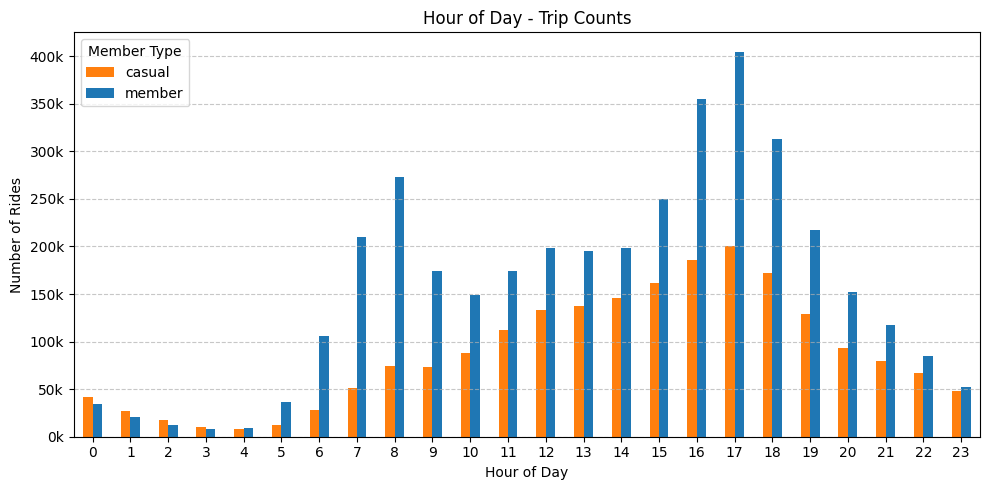

In [23]:
# Plotting trip counts bar chart

ax = hod_trip_count.plot(kind='bar', figsize=(10,5), rot=0, color=['#ff7f0e','#1f77b4'])

plt.title("Hour of Day - Trip Counts")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Rides")
plt.legend(title="Member Type", fontsize=10, loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.7)

ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{int(x/1000)}k')
)

plt.tight_layout()

In [24]:
# 5.2 Duration

hod_median_duration = (
    df.groupby([
    "start_hour",
    "member_casual",
    ],
    observed=True,
    )["ride_duration_min"]
    .median()
    .unstack()
)

hod_median_duration

member_casual,casual,member
start_hour,,
0,8.621033,7.639850
1,8.608892,7.226000
2,8.586950,7.249342
3,8.391517,7.770717
4,6.909417,7.082342
5,7.370667,6.906817
6,7.130542,7.470967
7,7.776608,8.241767
8,8.485692,8.326817


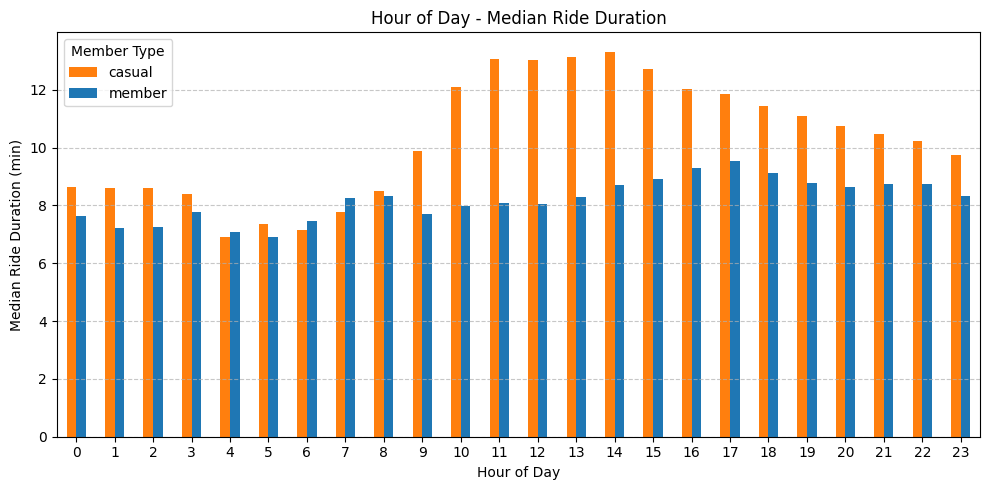

In [25]:
ax = hod_median_duration.plot(kind='bar', figsize=(10,5), rot=0, color=['#ff7f0e','#1f77b4'])

plt.title("Hour of Day - Median Ride Duration")
plt.xlabel("Hour of Day")
plt.ylabel("Median Ride Duration (min)")
plt.legend(loc="upper left", title="Member Type", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()

### 6. Weekend

Question:
- How does the usage behaivor for both rider groups affected by weekend?

Key Findings:
- Only 23.58% of member trips occur during weekends, compared with 37.75% for casual riders.
- Casual riders have higher share in total ride count during weekends (47.2%) than weekdays (31.3%).
- Average trip duration increases by approximately 12.8% for members during weekends, compared with approximately 24.4% for casual riders.

Insight:
- In terms of both usage frequency and trip duration, weekend riding has a significant greater impact on casual riders.

In [26]:
# 6.1 Trip Count

(
    df.groupby(
        ["member_casual"],
        observed=True,
    )["is_weekend"]
    .value_counts(sort=False)
    .unstack()
)

is_weekend,False,True
member_casual,,
casual,1304329,791110
member,2863701,883663


In [27]:
# weekend share by rider groups

(
    df.groupby(
        ["member_casual"],
        observed=True,
    )["is_weekend"]
    .value_counts(
        normalize=True,
        sort=False,
        )
    .unstack()
)*100

is_weekend,False,True
member_casual,,
casual,62.246097,37.753903
member,76.419078,23.580922


In [28]:
# rider group share by weekend status

pd.crosstab(
    df["is_weekend"],
    df["member_casual"],
    normalize="index",
)*100

member_casual,casual,member
is_weekend,,
False,31.293657,68.706343
True,47.236849,52.763151


In [29]:
# 6.2 Duration

# mean
(
    df.groupby([
    "member_casual",
    "is_weekend"
    ],
    observed=True,
    )["ride_duration_min"]
    .mean()
    .unstack()
)

is_weekend,False,True
member_casual,,
casual,17.276118,21.499479
member,11.708576,13.203792


In [30]:
# median
(
    df.groupby([
    "member_casual",
    "is_weekend"
    ],
    observed=True,
    )["ride_duration_min"]
    .median()
    .unstack()
)

is_weekend,False,True
member_casual,,
casual,10.345750,13.016475
member,8.413983,9.216100


### 7. Time Period

Key Findings:
- The majority of casual riders trip occur in the afternoon (12-5PM) - 46.0%, following by evening (6-11PM) - 28.1%.
- The majority of members trip also occur in the afternoon (12-5PM) - 42.8%, following by morning (6-11AM) - 29.0%.

In [31]:
# 7.1 Trip Counts

tp_trip_count = (
    df.groupby(
        ["time_period"],
        observed=True,
    )["member_casual"]
    .value_counts(sort=False)
    .unstack()
)

tp_trip_count

member_casual,casual,member
time_period,,
00-05 (Night),115632,120966
06-11 (Morning),426439,1086196
12-17 (Afternoon),964133,1602088
18-23 (Evening),589235,938114


In [32]:
# Normalize to 100%

pd.crosstab(
    df["member_casual"],
    df["time_period"],
    normalize="index"
)*100

time_period,00-05 (Night),06-11 (Morning),12-17 (Afternoon),18-23 (Evening)
member_casual,,,,
casual,5.518271,20.350819,46.011027,28.119883
member,3.228029,28.985602,42.752399,25.033971


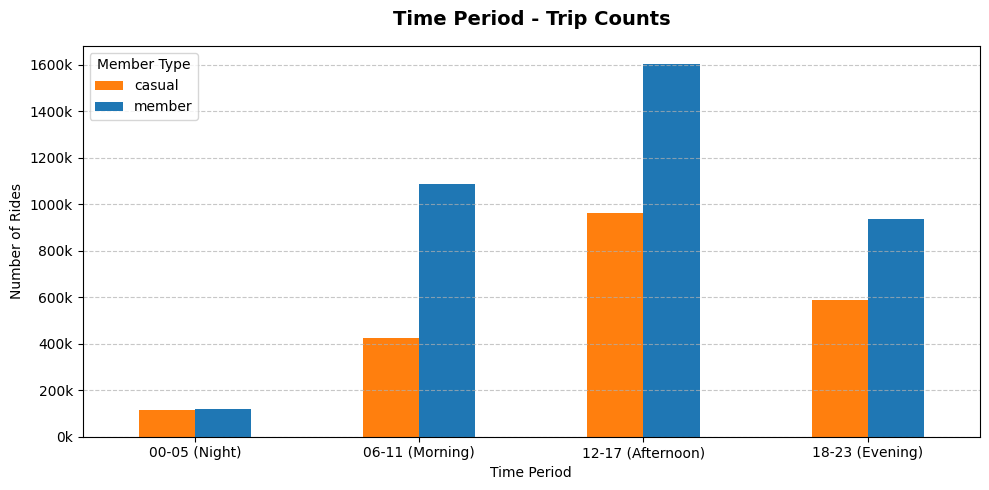

In [33]:
# Plotting trip count bar chart

ax = tp_trip_count.plot(kind='bar', figsize=(10,5), rot=0, color=['#ff7f0e','#1f77b4'])

plt.title("Time Period - Trip Counts", fontsize=14, pad=15, weight="bold")
plt.xlabel("Time Period")
plt.ylabel("Number of Rides")
plt.legend(loc="upper left", title="Member Type", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.7)

ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{int(x/1000)}k')
)

plt.tight_layout()

In [34]:
# 7.2 Duration

tp_median_duration = (
    df.groupby([
        "time_period",
        "member_casual",
        ],
        observed=True,
        )["ride_duration_min"]
        .median()
        .unstack()
)

tp_median_duration

member_casual,casual,member
time_period,,
00-05 (Night),8.330217,7.264350
06-11 (Morning),10.042217,8.037175
12-17 (Afternoon),12.536633,8.948208
18-23 (Evening),10.841933,8.832167


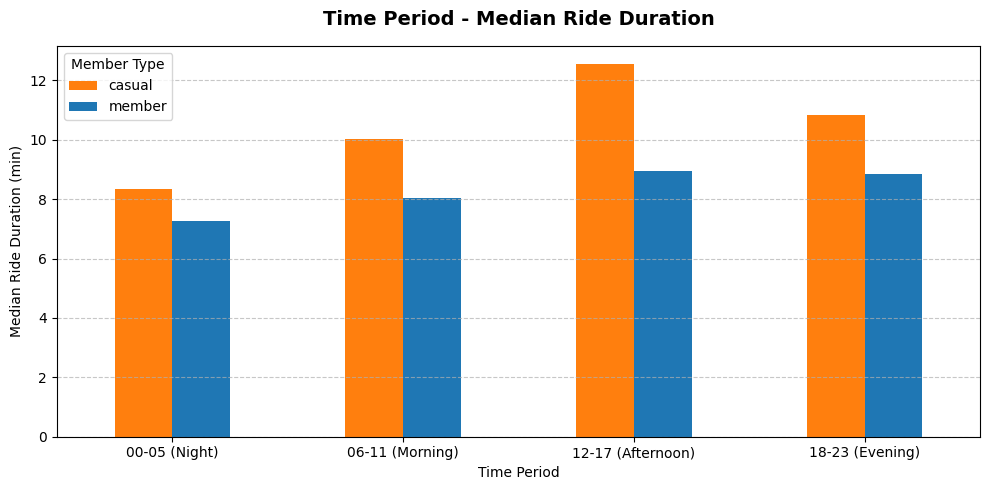

In [35]:
# Plotting median ride duration bar chart

ax = tp_median_duration.plot(kind='bar', figsize=(10,5), rot=0, color=['#ff7f0e','#1f77b4'])

plt.title("Time Period - Median Ride Duration", fontsize=14, pad=15, weight="bold")
plt.xlabel("Time Period")
plt.ylabel("Median Ride Duration (min)")
plt.legend(loc="upper left", title="Member Type", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()

### 8. Bike Type

Question:
- Is there any difference in bike type usage pattern for both rider groups?

Key Findings:
- Both rider groups display very similar bike preferences, with approximately 67% of rides taken using electric bikes and 33% using classic bikes.
- Casual riders take substantially longer trips when using classic bikes, with average ride duration approximately twice that of electric bike trips.
- Members also ride longer on classic bikes, although the difference is more modest (approximately 20%).

In [36]:
# Comparing bike type usage by members and casual riders
# 8.1 Trip Counts

(
    df.groupby(
        ["member_casual"],
        observed=True,
    )
    ["rideable_type"]
    .value_counts()
    .unstack()
)

rideable_type,classic_bike,electric_bike
member_casual,,
casual,657197,1438242
member,1283127,2464237


In [37]:
# Normalize to 100%

(
    df.groupby(
        ["member_casual"],
        observed=True,
    )
    ["rideable_type"]
    .value_counts(normalize=True)
    .unstack()
)*100

rideable_type,classic_bike,electric_bike
member_casual,,
casual,31.363213,68.636787
member,34.240789,65.759211


In [38]:
# 8.2 Duration

# mean

(
    df.groupby([
    "member_casual",
    "rideable_type",
    ],
    observed=True,
    )
    ["ride_duration_min"]
    .mean()
    .unstack()
)

rideable_type,classic_bike,electric_bike
member_casual,,
casual,29.405568,14.056705
member,13.982848,11.060540


In [39]:
# median

(
    df.groupby([
    "member_casual",
    "rideable_type",
    ],
    observed=True,
    )
    ["ride_duration_min"]
    .median()
    .unstack()
)

rideable_type,classic_bike,electric_bike
member_casual,,
casual,16.255567,9.618475
member,9.272900,8.269550


### 9. Monthly Trend

Question:
- How does usage vary throughout the year for members and casual riders?

Key Findings:
- Both rider groups demonstrate clear seasonal pattern, with the highest ride volumes occuring during summer, and the lowest volumes during winter.
- Members usage remains consistently high between July and October, whereas casual riders usage peak between June and August.
- Between June and August, casual riders have a significantly higher ratio in the rider mix - approximately 42%, compared to about 20% between December and February.
- Member ride duration remains relatively stable throughout the year, with a modest increase from June to September, whereas casual riders take noticeably longer trips during the summer months.

Insights:
- Seasonality appears to have stronger impact on casual riders than annual member, in terms of both ride counts and ride duration.

In [40]:
# Study Monthly Usage Trend
# 9.1 Trip Counts

mt_trip_count = (
    df.groupby(
        ["ride_month"],
        observed=True,
    )
    ["member_casual"]
    .value_counts()
    .unstack()
)

mt_trip_count

member_casual,casual,member
ride_month,,
January,24656,112933
February,41088,160251
March,87631,229121
April,131223,316675
May,244735,408525
June,291138,386709
July,322505,439965
August,337246,452355
September,264772,449202


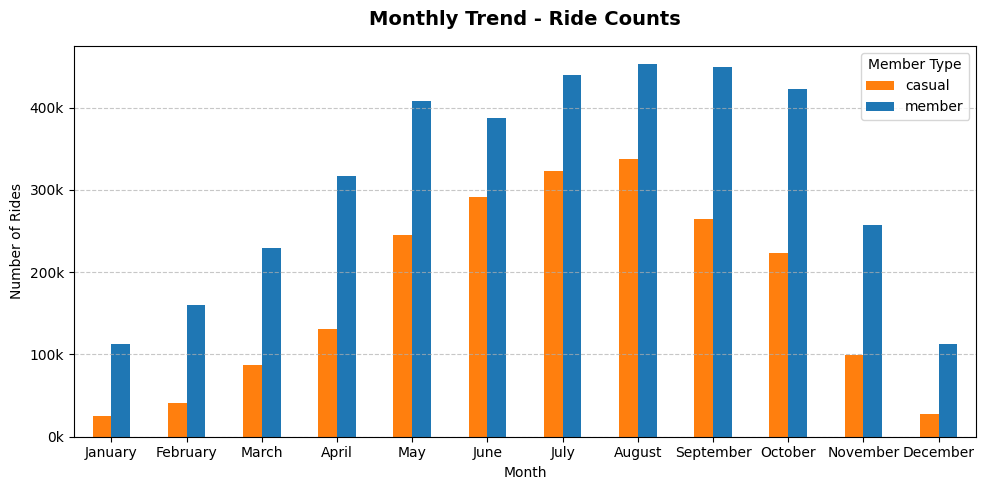

In [41]:
# Plotting monthly ride count bar chart

ax = mt_trip_count.plot(kind='bar', figsize=(10,5), rot=0, color=['#ff7f0e','#1f77b4'])

plt.title("Monthly Trend - Ride Counts", fontsize=14, pad=15, weight="bold")
plt.xlabel("Month")
plt.ylabel("Number of Rides")
plt.legend(loc="upper right", title="Member Type", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.7)

ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{int(x/1000)}k')
)

plt.tight_layout()

In [42]:
# Seasonal change in rider mix

month_pct = (
    df.groupby(
        ["ride_month"],
        observed=True
        )
        ["member_casual"]
        .value_counts()
        .unstack()
)

month_pct["casual_pct"] = (
    month_pct["casual"]
    / (month_pct["casual"] + month_pct["member"])
    * 100
)

month_pct["member_pct"] = (
    month_pct["member"]
    / (month_pct["casual"] + month_pct["member"])
    * 100
)

month_pct

member_casual,casual,member,casual_pct,member_pct
ride_month,,,,
January,24656,112933,17.920037,82.079963
February,41088,160251,20.407373,79.592627
March,87631,229121,27.665492,72.334508
April,131223,316675,29.297519,70.702481
May,244735,408525,37.463644,62.536356
June,291138,386709,42.950400,57.049600
July,322505,439965,42.297402,57.702598
August,337246,452355,42.710939,57.289061
September,264772,449202,37.084264,62.915736


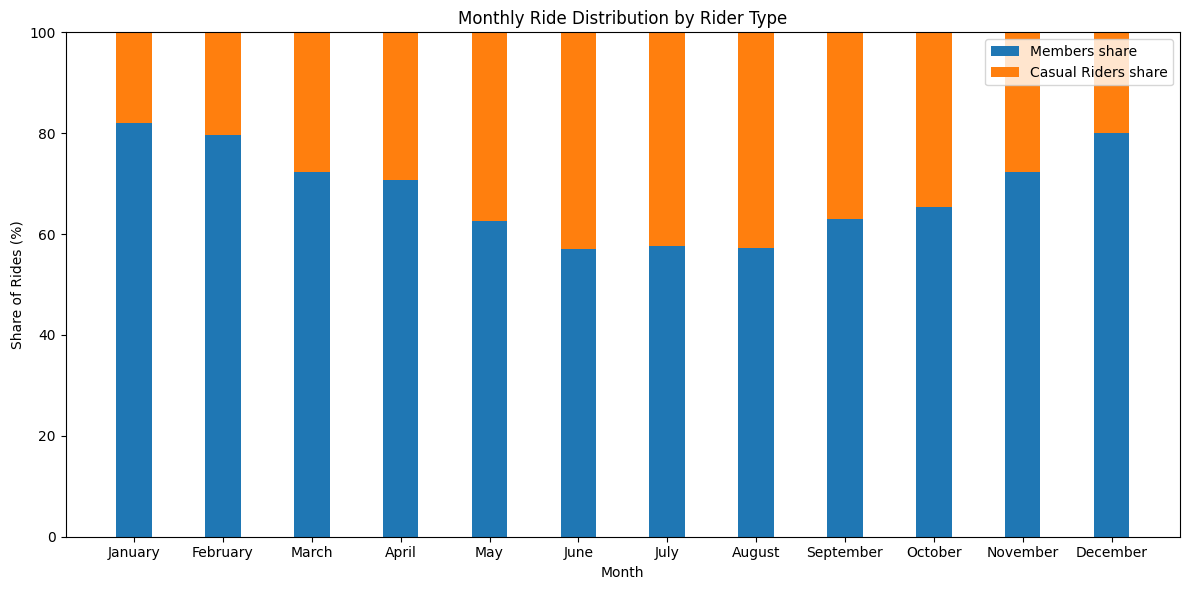

In [43]:
# Visualization

x = np.arange(len(month_pct.index))
bar_width = 0.4

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    x,
    month_pct["member_pct"],
    width=bar_width,
    label="Members share"
)

ax.bar(
    x,
    month_pct["casual_pct"],
    width=bar_width,
    bottom=month_pct["member_pct"],
    label="Casual Riders share"
)

ax.set_xlabel("Month")
ax.set_ylabel("Share of Rides (%)")
ax.set_title(
    "Monthly Ride Distribution by Rider Type"
)

ax.set_xticks(x)
ax.set_xticklabels(month_pct.index)

ax.set_ylim(0, 100)

ax.legend()

plt.tight_layout()
plt.show()

In [44]:
# 9.2 Duration

mt_duration = (
    df.groupby(
        ["ride_month", "member_casual"],
        observed=True,
    )
    ["ride_duration_min"]
    .median()
    .unstack()
)

mt_duration

member_casual,casual,member
ride_month,,
January,6.893083,6.989583
February,7.979567,7.291833
March,9.518467,7.690467
April,9.703000,7.979700
May,11.348283,8.673617
June,12.782708,9.418817
July,12.376533,9.364950
August,12.845308,9.468650
September,11.476075,9.124092


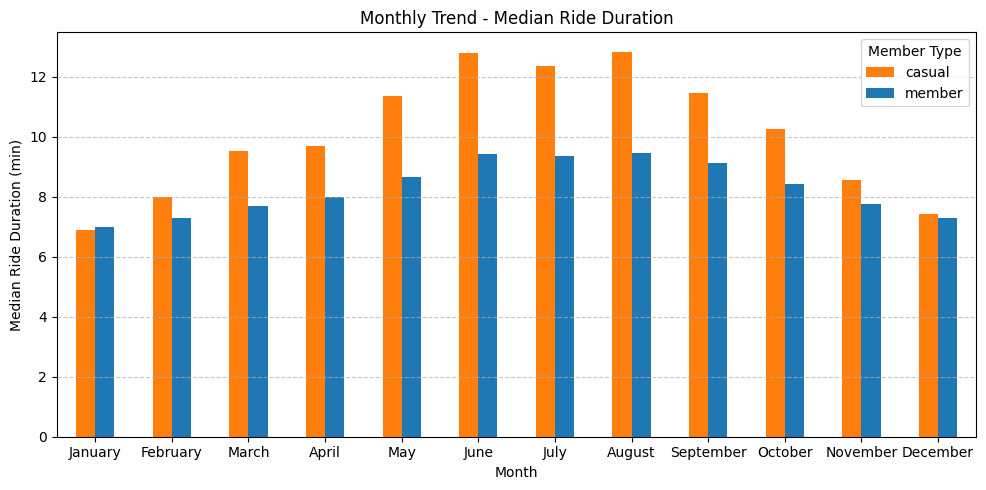

In [45]:
ax = mt_duration.plot(kind='bar', figsize=(10,5), rot=0, color=['#ff7f0e','#1f77b4'])

plt.title("Monthly Trend - Median Ride Duration")
plt.xlabel("Month")
plt.ylabel("Median Ride Duration (min)")
plt.legend(loc="upper right", title="Member Type", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()

### 10. Relationship/Multivariate Analysis

#### 10.1 Ride Duration x Hour of Day

- A bit duplicate with Section 5 - Hour of Day

In [46]:
# Studying the differences in Ride Duration at different Hour of Day

hour_duration = (
    df.groupby(
        ["member_casual", "start_hour"],
        observed=True,
    )
    .agg(
        median_duration=("ride_duration_min", "median"),
        mean_duration=("ride_duration_min", "mean"),
        ride_count=("ride_id", "count"),
    )
    .reset_index()
)

hour_duration.head()

,member_casual,start_hour,median_duration,mean_duration,ride_count
0,casual,0,8.621033,15.329651,41378
1,casual,1,8.608892,15.930386,26684
2,casual,2,8.586950,15.169681,17707
3,casual,3,8.391517,15.430705,9811
4,casual,4,6.909417,13.713883,7781


In [47]:
# Validation

hour_duration.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   member_casual    48 non-null     object 
 1   start_hour       48 non-null     int32  
 2   median_duration  48 non-null     float64
 3   mean_duration    48 non-null     float64
 4   ride_count       48 non-null     int64  
dtypes: float64(2), int32(1), int64(1), object(1)
memory usage: 1.8+ KB


In [48]:
hour_duration.describe()

,start_hour,median_duration,mean_duration,ride_count
count,48.000000,48.000000,48.000000,48.000000
mean,11.500000,9.237568,14.640123,121725.062500
std,6.995439,1.872059,3.666859,95744.776483
min,0.000000,6.906817,10.529610,7781.000000
25%,5.750000,7.921433,12.026323,40054.250000
50%,11.500000,8.630650,12.927621,109030.000000
75%,17.250000,10.278527,16.772100,177024.500000
max,23.000000,13.316558,22.934097,404857.000000


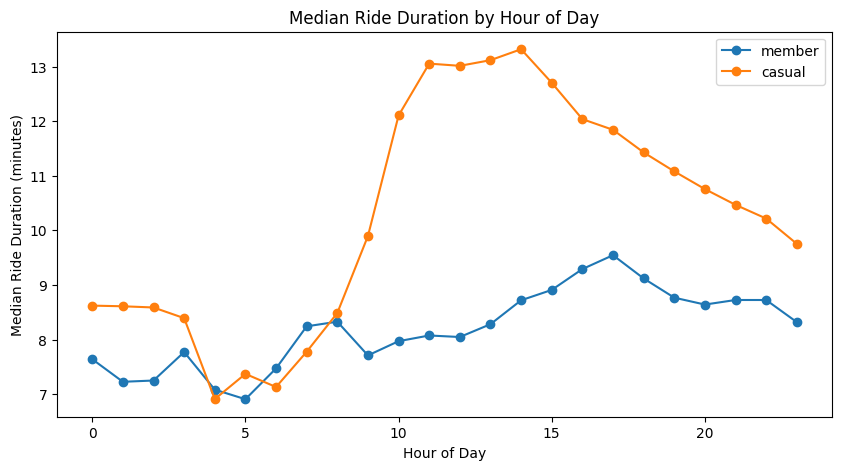

In [49]:
fig, ax = plt.subplots(figsize=(10, 5))

for rider in ["member", "casual"]:

    subset = hour_duration[
        hour_duration["member_casual"] == rider
    ]

    ax.plot(
        subset["start_hour"],
        subset["median_duration"],
        marker="o",
        label=rider
    )

ax.set_title("Median Ride Duration by Hour of Day")

ax.set_xlabel("Hour of Day")

ax.set_ylabel("Median Ride Duration (minutes)")

ax.legend()

plt.show()

#### 10.2 Weekend x Hour of Day

- Further study the effect of weekends on how different rider groups use cyclistic bike across the day

In [50]:
weekend_hour = (
    df.groupby(
        ["member_casual", "is_weekend", "start_hour"],
        observed=True
    )
    .agg(
        ride_count=("ride_id", "count"),
        median_duration=("ride_duration_min", "median"),
        mean_duration=("ride_duration_min", "mean")
    )
    .reset_index()
)

weekend_hour.head()

,member_casual,is_weekend,start_hour,ride_count,median_duration,mean_duration
0,casual,False,0,18493,8.185067,14.810180
1,casual,False,1,10576,8.359317,15.770334
2,casual,False,2,6757,8.076200,14.522619
3,casual,False,3,3873,7.886967,14.984075
4,casual,False,4,4236,6.173983,11.307204


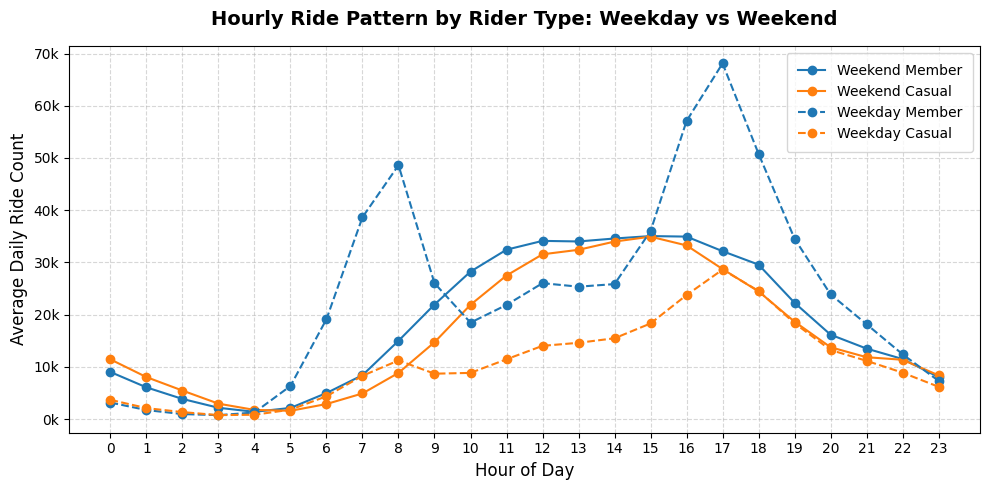

In [51]:
# Average Daily Ride Count

colors = {"member": "#1f77b4", "casual": "#ff7f0e"}
styles = {
    True: {"linestyle": "-", "label_prefix": "Weekend"},
    False: {"linestyle": "--", "label_prefix": "Weekday"}
}

fig, ax = plt.subplots(figsize=(10,5))

for is_weekend, style in styles.items():
    divisor = 2 if is_weekend else 5

    for rider in ["member", "casual"]:
        subset = weekend_hour[
            (weekend_hour["member_casual"] == rider)
            & (weekend_hour["is_weekend"] == is_weekend)
        ]

        ax.plot(
            subset["start_hour"],
            subset["ride_count"] / divisor,
            marker="o",
            linestyle=style["linestyle"],
            color=colors[rider],
            label=f"{style['label_prefix']} {rider.capitalize()}"
        )

ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x/1000)}k'))

ax.set_title(
    "Hourly Ride Pattern by Rider Type: Weekday vs Weekend",
    fontsize=14,
    pad=15,
    weight='bold'
)
ax.set_xlabel("Hour of Day", fontsize=12)
ax.set_ylabel("Average Daily Ride Count", fontsize=12)

ax.set_xticks(range(0,24))
ax.grid(axis="both", linestyle="--", alpha=0.5)

ax.legend(frameon=True, borderpad=0.8, fontsize=10)

plt.tight_layout()
plt.show()

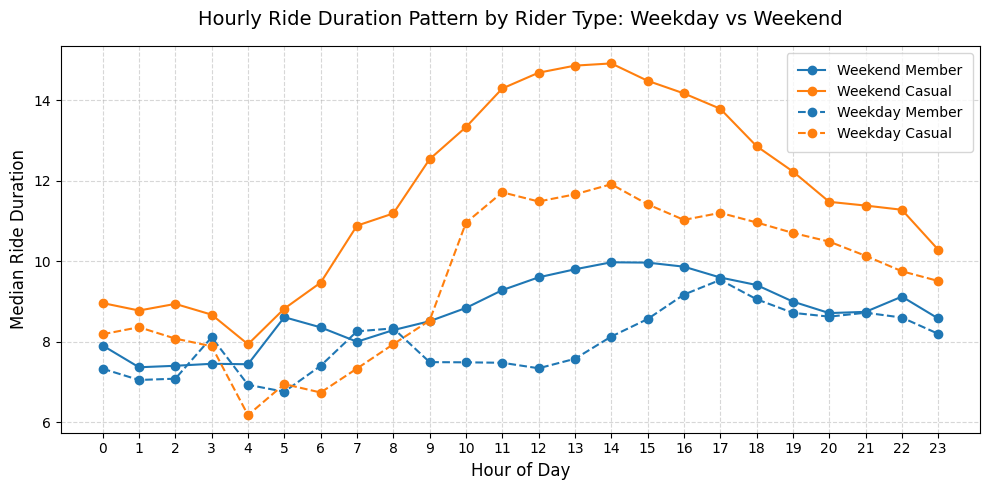

In [52]:
# Ride Duration

colors = {"member": "#1f77b4", "casual": "#ff7f0e"}
styles = {
    True: {"linestyle": "-", "label_prefix": "Weekend"},
    False: {"linestyle": "--", "label_prefix": "Weekday"}
}

fig, ax = plt.subplots(figsize=(10,5))

for is_weekend, style in styles.items():

    for rider in ["member", "casual"]:
        subset_hour = weekend_hour[
            (weekend_hour["member_casual"] == rider)
            & (weekend_hour["is_weekend"] == is_weekend)
        ]

        ax.plot(
            subset_hour["start_hour"],
            subset_hour["median_duration"],
            marker="o",
            linestyle=style["linestyle"],
            color=colors[rider],
            label=f"{style['label_prefix']} {rider.capitalize()}"
        )

ax.set_title(
    "Hourly Ride Duration Pattern by Rider Type: Weekday vs Weekend",
    fontsize=14,
    pad=15
)
ax.set_xlabel("Hour of Day", fontsize=12)
ax.set_ylabel("Median Ride Duration", fontsize=12)

ax.set_xticks(range(0,24))
ax.grid(axis="both", linestyle="--", alpha=0.5)

ax.legend(frameon=True, borderpad=0.8, fontsize=10)

plt.tight_layout()
plt.show()

#### 10.3 Ride Count x Ride Duration

- Further examine correlation between ride count and ride duration

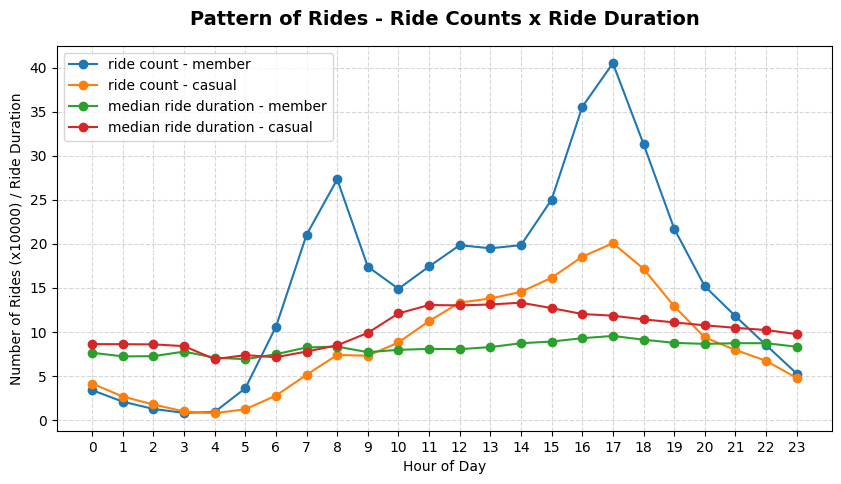

In [53]:
fig, ax = plt.subplots(figsize=(10, 5))

for rider in ["member", "casual"]:

    subset_hour = hour_duration[
        hour_duration["member_casual"] == rider
    ]

    ax.plot(
        subset_hour["start_hour"],
        (subset_hour["ride_count"])/10000,
        marker="o",
        label="ride count - " + f'{rider}'
    )

for rider in ["member", "casual"]:

    subset_hour = hour_duration[
        hour_duration["member_casual"] == rider
    ]

    ax.plot(
        subset_hour["start_hour"],
        subset_hour["median_duration"],
        marker="o",
        label="median ride duration - " + f'{rider}'
    )

ax.set_title("Pattern of Rides - Ride Counts x Ride Duration", fontsize=14, pad=15, weight="bold")

ax.set_xlabel("Hour of Day")
ax.set_ylabel("Number of Rides (x10000) / Ride Duration")

ax.set_xticks(range(0,24))
ax.grid(axis="both", linestyle="--", alpha=0.5)

ax.legend()

plt.show()

#### 10.4 Monthly and Seasonal Trend

- Examining how seasonal changes affect ride volume and usage patterns across rider groups

Key Findings:
- Ride volume for both members and casual riders shows a clear seasonal pattern, with substantially higher usage during the warmer months and lower usage during winter.

- Despite substantial seasonal variation in overall ride volume, both rider groups maintain broadly consistent hourly usage patterns throughout the year. Members consistently exhibit a bimodal pattern around the morning and evening commuting hours. Casual riders consistently show greater concentration of trips during the afternoon, with no comparable morning commuting peak observed across the year.

- Casual riders consistently have a higher proportion of weekend trips than members, with the difference becoming more pronounced during the warmer months.

- The weekend share of casual riders varies more noticeably across the year, increasing during warmer months and declining during winter, while members show a comparatively more stable weekday–weekend distribution.

##### 10.4.1 Month x Hour
- Examining hourly usage trends in different seasons

In [54]:
month_hour = (
    df.groupby(
        ["member_casual", "ride_month", "start_hour"],
        observed=True
    )
    .agg(
        ride_count=("ride_id", "count")
    )
    .reset_index()
)

month_hour.head()

,member_casual,ride_month,start_hour,ride_count
0,casual,January,0,490
1,casual,January,1,410
2,casual,January,2,288
3,casual,January,3,146
4,casual,January,4,130


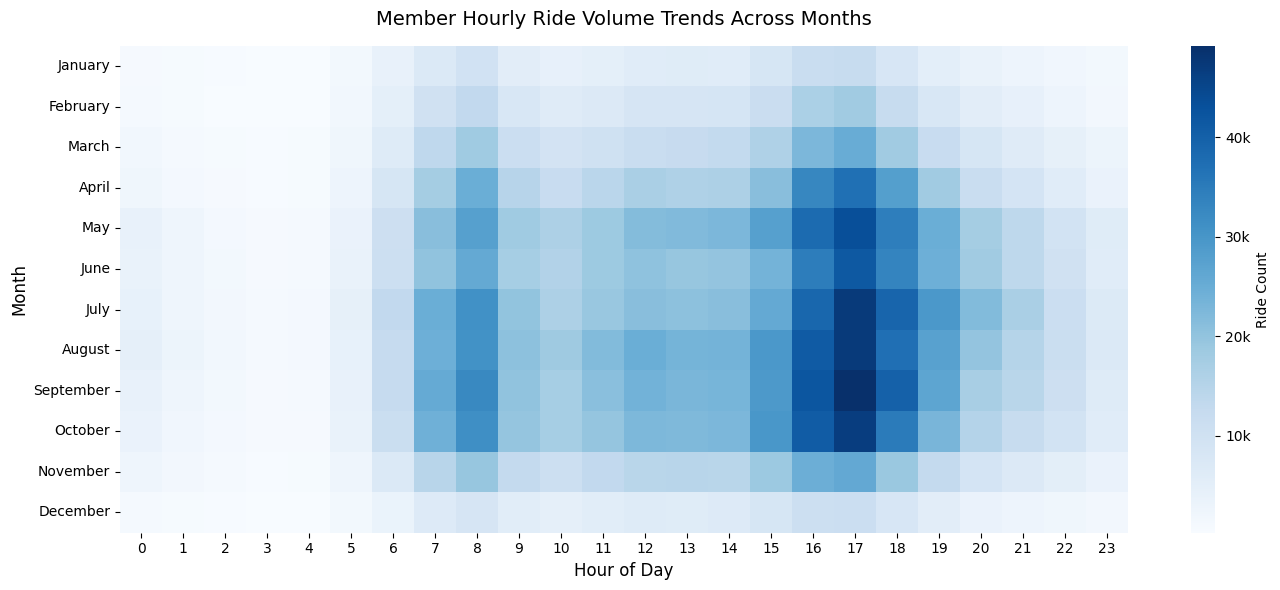

In [55]:
# member

member_hour_month = (
    month_hour
    .query("member_casual == 'member'")
    .pivot(
        index="ride_month",
        columns="start_hour",
        values="ride_count"
    )
)

# Heatmap

fig, ax = plt.subplots(figsize=(14,6))

cbar_fmt_k = ticker.FuncFormatter(lambda x, pos: f'{int(x/1000)}k')

sns.heatmap(
    member_hour_month,
    cmap="Blues",
    ax=ax,
    cbar_kws={'format': cbar_fmt_k, 'label': 'Ride Count'},
)

ax.set_title(
    "Member Hourly Ride Volume Trends Across Months",
    fontsize=14,
    pad=15,
)
ax.set_xlabel("Hour of Day", fontsize=12)
ax.set_ylabel("Month", fontsize=12)

plt.tight_layout()
plt.show()

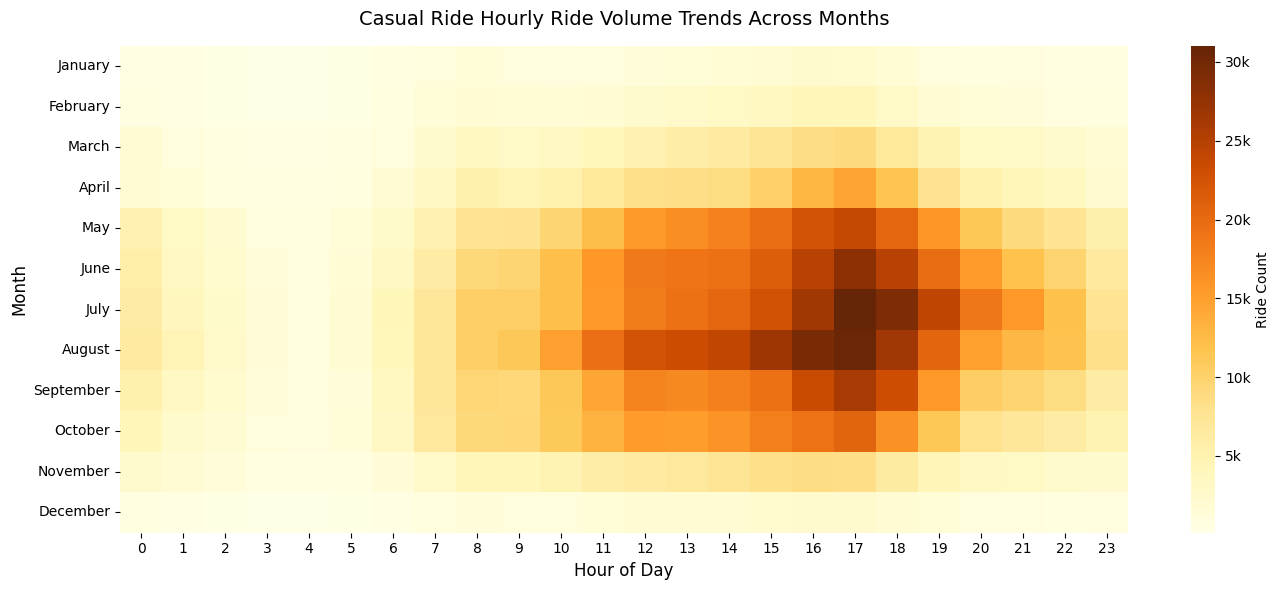

In [56]:
# casual

casual_hour_month = (
    month_hour
    .query("member_casual == 'casual'")
    .pivot(
        index="ride_month",
        columns="start_hour",
        values="ride_count"
    )
)

# Heatmap

fig, ax = plt.subplots(figsize=(14,6))

cbar_fmt_k = ticker.FuncFormatter(lambda x, pos: f'{int(x/1000)}k')

sns.heatmap(
    casual_hour_month,
    cmap="YlOrBr",
    ax=ax,
    cbar_kws={'format': cbar_fmt_k, 'label': 'Ride Count'},
)

ax.set_title(
    "Casual Ride Hourly Ride Volume Trends Across Months",
    fontsize=14,
    pad=15,
)
ax.set_xlabel("Hour of Day", fontsize=12)
ax.set_ylabel("Month", fontsize=12)

plt.tight_layout()
plt.show()

In [57]:
# Monthly Hourly Share - Members

month_hour["hour_share"] = (
    month_hour["ride_count"]
    / month_hour.groupby(
        ["member_casual", "ride_month"],
        observed=True
    )["ride_count"]
    .transform("sum")
    * 100
)

member_hour_share = (
    month_hour
    .query("member_casual == 'member'")
    .pivot(
        index="ride_month",
        columns="start_hour",
        values="hour_share"
    )
)

member_hour_share.head()

start_hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
ride_month,,,,,,,,,,,,,,,,,,,,,
January,0.753544,0.541029,0.394924,0.190378,0.264759,1.370724,3.502962,6.393171,8.529836,4.828527,...,5.272153,7.430069,10.527481,10.780728,7.249431,4.562882,3.247058,2.489086,1.778931,1.218422
February,0.655222,0.385645,0.232760,0.169110,0.234008,1.117622,3.065191,6.331318,8.212741,4.931014,...,5.412759,7.248005,10.402431,11.251100,7.603697,4.924150,3.470181,2.672682,1.754123,1.024019
March,0.829693,0.485770,0.263180,0.220408,0.284129,0.947534,2.784118,5.928745,7.978317,4.937566,...,5.609263,6.988447,9.936671,10.994627,7.935545,5.223877,3.613811,2.738728,1.993270,1.282728
April,0.673877,0.415252,0.256099,0.186627,0.198626,0.854188,2.638352,5.540381,7.837057,4.678614,...,5.183232,6.709718,10.358885,11.724323,8.837767,5.721323,3.748638,2.799716,1.848267,1.104287
May,0.968607,0.582339,0.322135,0.221529,0.247476,0.888563,2.674255,5.173980,6.805214,4.483936,...,5.579096,6.830182,9.313751,10.617955,8.465088,6.070865,4.293740,3.347408,2.326173,1.460865


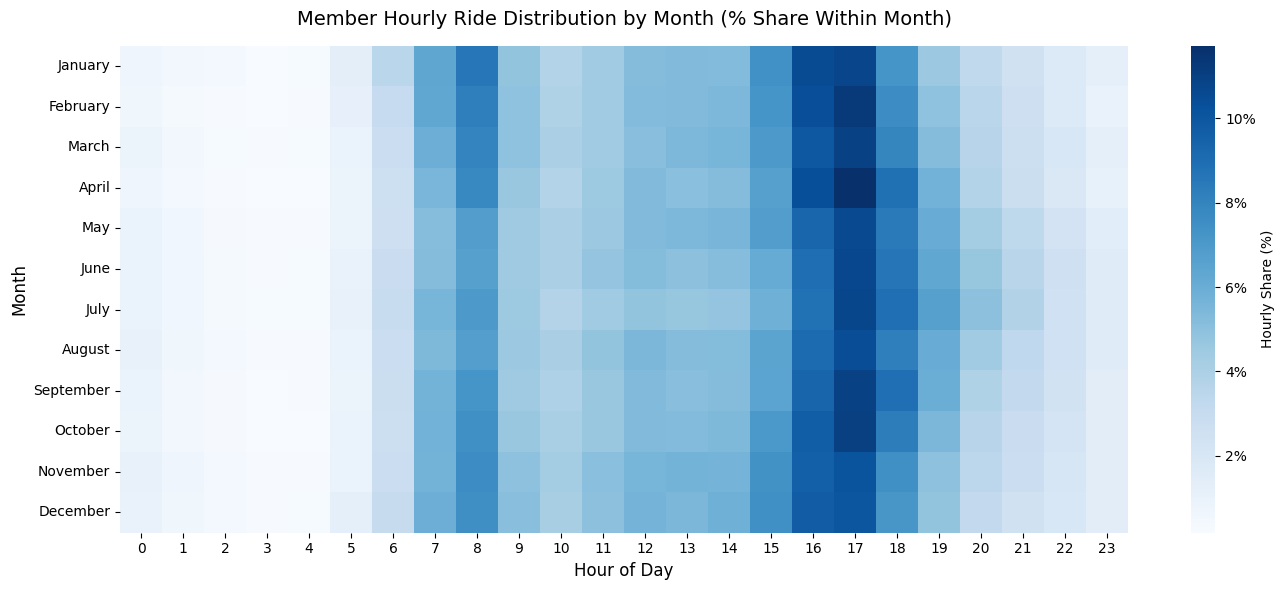

In [58]:
fig, ax = plt.subplots(figsize=(14,6))

cbar_fmt_pct = ticker.FuncFormatter(lambda x, pos: f'{x:.0f}%')

sns.heatmap(
    member_hour_share,
    cmap="Blues",
    ax=ax,
    cbar_kws={'format': cbar_fmt_pct, 'label': 'Hourly Share (%)'},
)

ax.set_title(
    "Member Hourly Ride Distribution by Month (% Share Within Month)",
    fontsize=14,
    pad=15,
)
ax.set_xlabel("Hour of Day", fontsize=12)
ax.set_ylabel("Month", fontsize=12)

plt.tight_layout()
plt.show()

In [59]:
# Monthly Hourly Share - Casuals

casual_hour_share = (
    month_hour
    .query("member_casual == 'casual'")
    .pivot(
        index="ride_month",
        columns="start_hour",
        values="hour_share"
    )
)

casual_hour_share.head()

start_hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
ride_month,,,,,,,,,,,,,,,,,,,,,
January,1.987346,1.662881,1.168073,0.592148,0.527255,1.131570,2.283420,4.209929,5.617294,4.307268,...,6.817813,8.281960,9.961064,8.991726,6.444679,4.664179,3.297372,3.500162,2.883679,2.563271
February,1.613610,1.053836,0.805588,0.425915,0.477025,0.786118,1.788843,3.460864,4.787286,3.976830,...,7.632399,8.569412,10.258470,10.141647,7.104264,4.573111,3.473033,3.215051,2.348618,1.837519
March,2.035809,1.323732,0.794239,0.481565,0.449613,0.602527,1.348838,2.661159,4.165193,3.341283,...,7.351280,8.426242,9.858383,10.248656,7.973206,5.630428,3.681346,3.344707,2.928188,2.117972
April,1.523361,1.026497,0.645466,0.384079,0.383317,0.560877,1.425817,2.516327,4.128087,3.592358,...,6.684042,7.727304,9.870983,11.055989,8.872682,6.008093,3.971103,3.304299,2.681695,1.615570
May,2.121478,1.316526,0.844996,0.482154,0.327293,0.577359,1.104869,2.118209,3.149120,3.166691,...,7.294829,7.994770,9.215682,9.680266,8.304493,6.484974,4.605798,3.696651,3.134819,2.271436


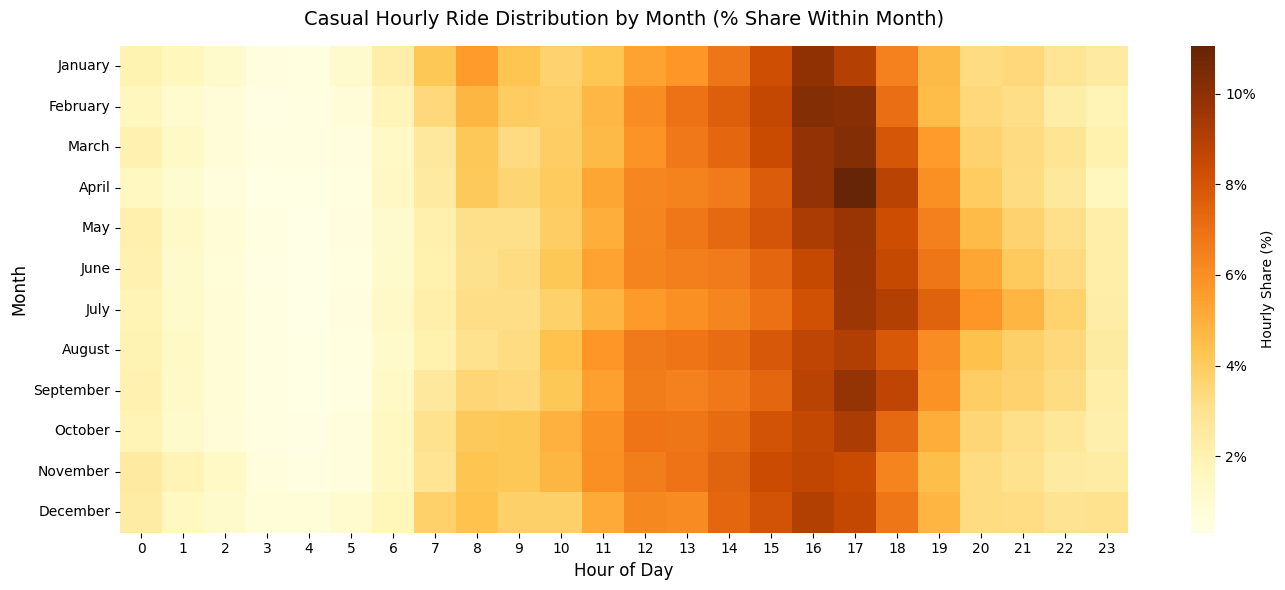

In [60]:
fig, ax = plt.subplots(figsize=(14,6))

cbar_fmt_pct = ticker.FuncFormatter(lambda x, pos: f'{x:.0f}%')

sns.heatmap(
    casual_hour_share,
    cmap="YlOrBr",
    ax=ax,
    cbar_kws={'format': cbar_fmt_pct, 'label': 'Hourly Share (%)'},
)

ax.set_title(
    "Casual Hourly Ride Distribution by Month (% Share Within Month)",
    fontsize=14,
    pad=15,
)
ax.set_xlabel("Hour of Day", fontsize=12)
ax.set_ylabel("Month", fontsize=12)

plt.tight_layout()
plt.show()

##### 10.4.2 Month x Weekend
- Examining weekend usage trend in different seasons

In [61]:
month_weekend = (
    df.groupby(
        ["member_casual", "ride_month", "is_weekend"],
        observed=True
    )
    .agg(
        ride_count=("ride_id", "count"),
        median_duration=("ride_duration_min", "median"),
        mean_duration=("ride_duration_min", "mean")
    )
    .reset_index()
)

month_weekend.head()

,member_casual,ride_month,is_weekend,ride_count,median_duration,mean_duration
0,casual,January,False,18329,6.715067,11.784641
1,casual,January,True,6327,7.537383,15.049960
2,casual,February,False,29915,7.622483,13.108671
3,casual,February,True,11173,9.079033,15.741487
4,casual,March,False,52448,8.621608,14.916415


In [62]:
# Pivot

plot_data = (
    month_weekend
    .assign(
        rider_period=lambda x:
        x["member_casual"] + "_" +
        x["is_weekend"].map({
            False: "weekday",
            True: "weekend"
        })
    )
    .pivot(
        index="ride_month",
        columns="rider_period",
        values="ride_count"
    )
    .reindex(
        columns=[
            "member_weekday",
            "member_weekend",
            "casual_weekday",
            "casual_weekend"
        ]
    )
)

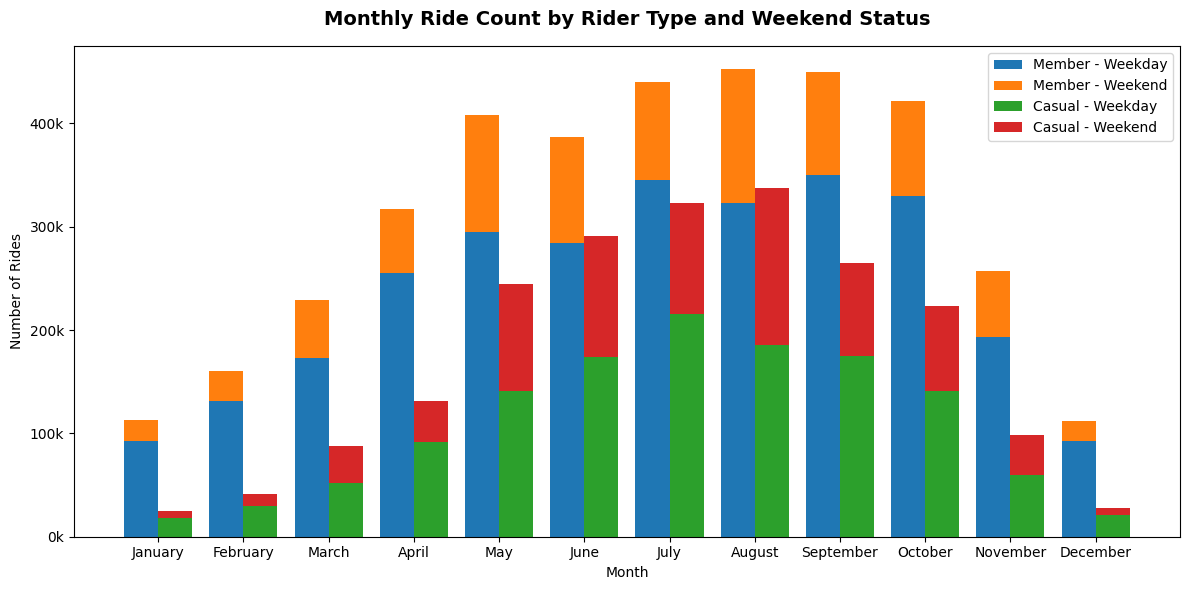

In [63]:
fig, ax = plt.subplots(figsize=(12, 6))

bar_width = 0.4

# Member
ax.bar(
    x - bar_width / 2,
    plot_data["member_weekday"],
    width=bar_width,
    label="Member - Weekday"
)

ax.bar(
    x - bar_width / 2,
    plot_data["member_weekend"],
    width=bar_width,
    bottom=plot_data["member_weekday"],
    label="Member - Weekend"
)

# Casual
ax.bar(
    x + bar_width / 2,
    plot_data["casual_weekday"],
    width=bar_width,
    label="Casual - Weekday"
)

ax.bar(
    x + bar_width / 2,
    plot_data["casual_weekend"],
    width=bar_width,
    bottom=plot_data["casual_weekday"],
    label="Casual - Weekend"
)

ax.set_xlabel("Month")
ax.set_ylabel("Number of Rides")
ax.set_title(
    "Monthly Ride Count by Rider Type and Weekend Status",
    fontsize=14,
    pad=15,
    weight='bold'
)

ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x/1000)}k'))

ax.set_xticks(x)
ax.set_xticklabels(plot_data.index)

ax.legend()

plt.tight_layout()
plt.show()

In [64]:
# Normalizing ride to 100%

month_weekend_pct = (
    month_weekend
    .copy()
)

month_weekend_pct["ride_pct"] = (
    month_weekend_pct["ride_count"]
    / month_weekend_pct.groupby(
        ["member_casual", "ride_month"],
        observed=True
    )["ride_count"]
    .transform("sum")
    *100
)

# Validation
(
    month_weekend_pct
    .groupby(
        ["member_casual", "ride_month"],
        observed=True
    )["ride_pct"]
    .sum()
)

member_casual  ride_month
casual         January       100.0
               February      100.0
               March         100.0
               April         100.0
               May           100.0
               June          100.0
               July          100.0
               August        100.0
               September     100.0
               October       100.0
               November      100.0
               December      100.0
member         January       100.0
               February      100.0
               March         100.0
               April         100.0
               May           100.0
               June          100.0
               July          100.0
               August        100.0
               September     100.0
               October       100.0
               November      100.0
               December      100.0
Name: ride_pct, dtype: float64

In [65]:
# Pivot

plot_pct = (
    month_weekend_pct
    .assign(
        rider_period=lambda x:
        x["member_casual"] + "_" +
        x["is_weekend"].map({
            False: "weekday",
            True: "weekend"
        })
    )
    .pivot(
        index="ride_month",
        columns="rider_period",
        values="ride_pct"
    )
    .reindex(
        columns=[
            "member_weekday",
            "member_weekend",
            "casual_weekday",
            "casual_weekend"
        ]
    )
)

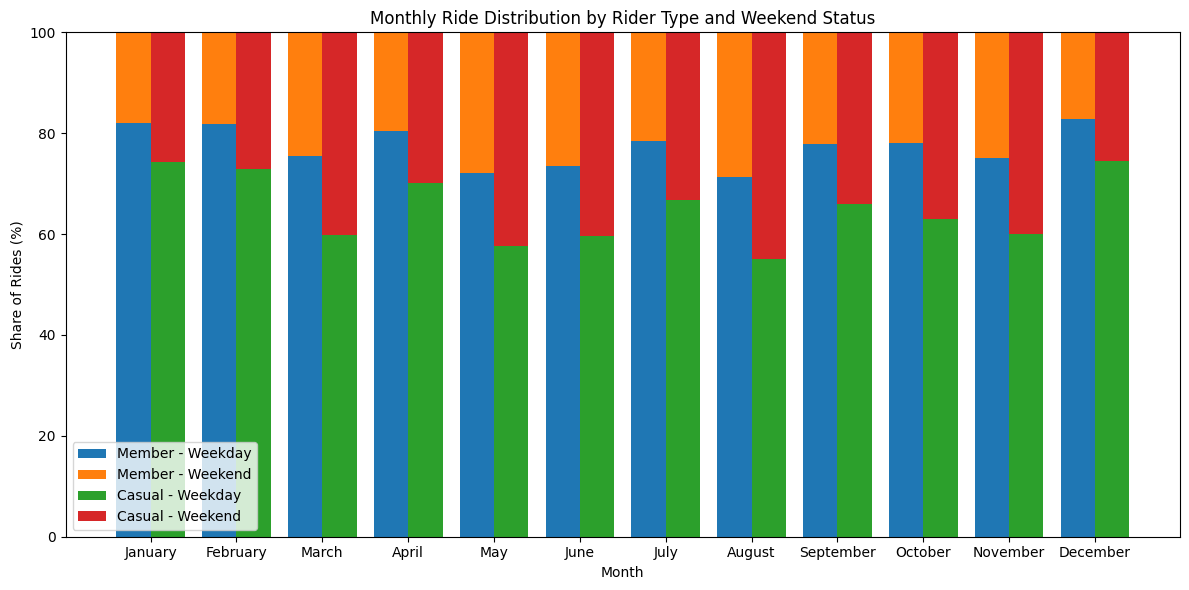

In [66]:
# Visualization

x = np.arange(len(plot_pct.index))
bar_width = 0.4

fig, ax = plt.subplots(figsize=(12, 6))

# Member
ax.bar(
    x - bar_width / 2,
    plot_pct["member_weekday"],
    width=bar_width,
    label="Member - Weekday"
)

ax.bar(
    x - bar_width / 2,
    plot_pct["member_weekend"],
    width=bar_width,
    bottom=plot_pct["member_weekday"],
    label="Member - Weekend"
)

# Casual
ax.bar(
    x + bar_width / 2,
    plot_pct["casual_weekday"],
    width=bar_width,
    label="Casual - Weekday"
)

ax.bar(
    x + bar_width / 2,
    plot_pct["casual_weekend"],
    width=bar_width,
    bottom=plot_pct["casual_weekday"],
    label="Casual - Weekend"
)

ax.set_xlabel("Month")
ax.set_ylabel("Share of Rides (%)")
ax.set_title(
    "Monthly Ride Distribution by Rider Type and Weekend Status"
)

ax.set_xticks(x)
ax.set_xticklabels(plot_pct.index)

ax.set_ylim(0, 100)

ax.legend()

plt.tight_layout()
plt.show()

In [67]:
month_weekend_pct["ride_pct_total"] = (
    month_weekend_pct["ride_count"]
    / month_weekend_pct.groupby(
        ["ride_month"],
        observed=True
    )["ride_count"]
    .transform("sum")
    *100
)

# Validation
(
    month_weekend_pct
    .groupby(
        ["ride_month"],
        observed=True
    )["ride_pct_total"]
    .sum()
)

ride_month
January      100.0
February     100.0
March        100.0
April        100.0
May          100.0
June         100.0
July         100.0
August       100.0
September    100.0
October      100.0
November     100.0
December     100.0
Name: ride_pct_total, dtype: float64

In [68]:
# Pivot

plot_pct_total = (
    month_weekend_pct
    .assign(
        rider_period=lambda x:
        x["member_casual"].map({
            "member": "Member (",
            "casual": "Casual ("
        }) +
        x["is_weekend"].map({
            False: "Weekday",
            True: "Weekend"
        }) + ")"
    )
    .pivot(
        index="ride_month",
        columns="rider_period",
        values="ride_pct_total"
    )
    .reindex(
        columns=[
            "Member (Weekday)",
            "Member (Weekend)",
            "Casual (Weekday)",
            "Casual (Weekend)"
        ]
    )
)

plot_pct_total

rider_period,Member (Weekday),Member (Weekend),Casual (Weekday),Casual (Weekend)
ride_month,,,,
January,67.306979,14.772983,13.321559,4.598478
February,65.107605,14.485023,14.858026,5.549347
March,54.579608,17.754900,16.558064,11.107428
April,56.902911,13.799570,20.549321,8.748197
May,45.061844,17.474512,21.594465,15.869179
June,41.970386,15.079214,25.632628,17.317772
July,45.249780,12.452818,28.241767,14.055635
August,40.885333,16.403728,23.548222,19.162716
September,48.973632,13.942104,24.431282,12.652982


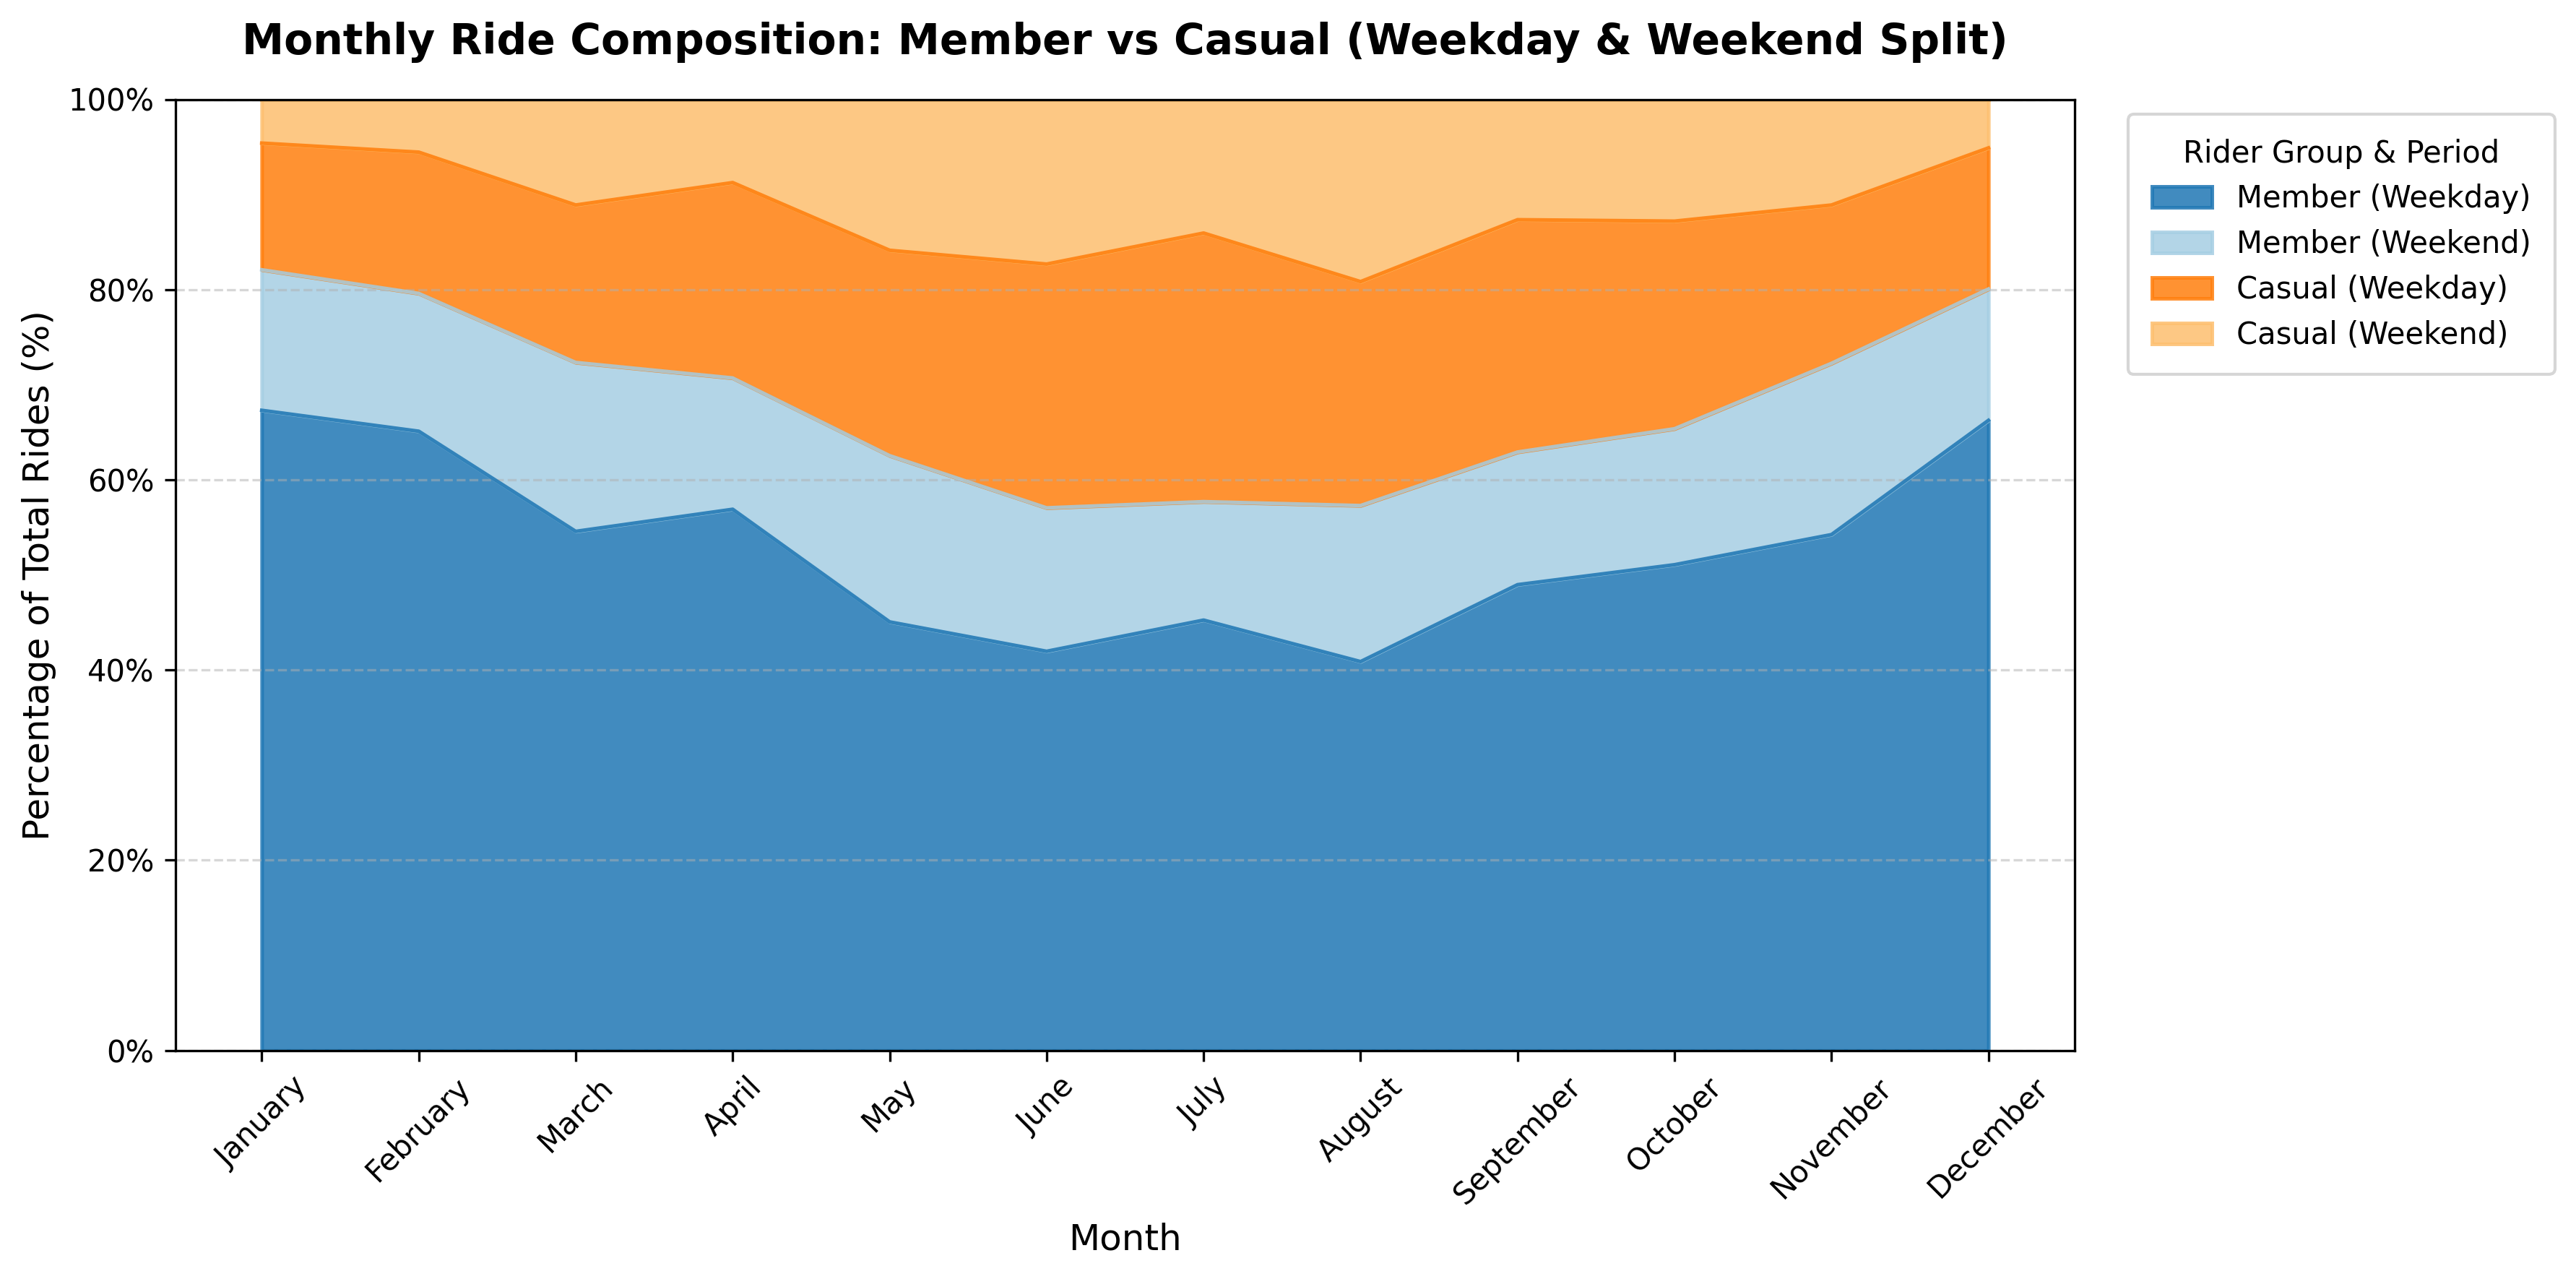

In [69]:
month_order = [
    'January',
    'February',
    'March',
    'April',
    'May',
    'June',
    'July',
    'August',
    'September',
    'October',
    'November',
    'December',
]
plot_pct_total = plot_pct_total.reindex(month_order)

color_map = {
    'Member (Weekday)': '#1f77b4',
    'Member (Weekend)': '#a6cee3',
    'Casual (Weekday)': '#ff7f0e',
    'Casual (Weekend)': '#fdbf6f',
}

cols = ['Member (Weekday)', 'Member (Weekend)', 'Casual (Weekday)', 'Casual (Weekend)']
plot_data = plot_pct_total[cols]

fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

plot_data.plot.area(
    ax=ax,
    color=[color_map[c] for c in cols],
    alpha=0.85,
    linewidth=1.2,
)

# Formatting y-axis to pct
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f'{int(y)}%'))
ax.set_ylim(0, 100)

# Title ,labels, legend
ax.set_title(
    'Monthly Ride Composition: Member vs Casual (Weekday & Weekend Split)',
    fontsize=14,
    pad=15,
    weight='bold',
)
ax.set_xlabel('Month', fontsize=12)
ax.set_ylabel('Percentage of Total Rides (%)', fontsize=12)

# x axis labels rotate 45 to prevent overlap
plt.xticks(range(len(month_order)), month_order, rotation=45)

ax.legend(
    title='Rider Group & Period',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=True,
    borderpad=0.8,
    fontsize=10,
)

ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 11. Station Analysis (Supporting Analysis)

#### 11.1 Missingness

Key Findings:
- Station information is missing for approximately 21.4% of start stations and 22.4% of end stations.
- Missingness in start station is broadly consistent between members and casual riders (21.0% vs 22.0%).
- End station information shows a larger difference, with missingness among casual riders approximately 3.6% higher than among members (24.7% vs 21.1%).
- This suggests a potential rider-type-related missingness pattern, however the difference is not large enough by itself to establish substantial bias.

Limitation:
- The overall level of missingness limits the completeness of station analysis. Station findings therefore represent only the rides with available station information and may not fully reflect the real usage pattern.

In [70]:
# Counting rows with missing start/end station information

start_station_missing = (
    df["start_station_name"]
    .isna()
)

print(f"Missing start station: {start_station_missing.sum()}")
print(f"pct: {start_station_missing.mean():.1%}")

end_station_missing = (
    df["end_station_name"]
    .isna()
)

print("")
print(f"Missing End Station: {end_station_missing.sum()}")
print(f"pct: {end_station_missing.mean():.1%}")

Missing start station: 1249657
pct: 21.4%

Missing End Station: 1308607
pct: 22.4%


In [71]:
# Calculating member/casuals distribution in the records with missing START station information

df[df["start_station_name"].isna()]["member_casual"].value_counts(normalize=True)

member_casual
member    0.631041
casual    0.368959
Name: proportion, dtype: float64

In [72]:
# Calculating member/casuals distribution in the records with missing END station information

df[df["end_station_name"].isna()]["member_casual"].value_counts(normalize=True)

member_casual
member    0.604876
casual    0.395124
Name: proportion, dtype: float64

In [73]:
pd.crosstab(
    df["member_casual"],
    df["start_station_name"].isna(),
    normalize="index"
) * 100

start_station_name,False,True
member_casual,,
casual,77.996401,22.003599
member,78.956274,21.043726


In [74]:
pd.crosstab(
    df["member_casual"],
    df["end_station_name"].isna(),
    normalize="index"
) * 100

end_station_name,False,True
member_casual,,
casual,75.324407,24.675593
member,78.877285,21.122715


#### 11.2 Top Stations by Rider Type

Question:
- What are the most frequently used start station for members and casual riders?
- How does these vary across weekday and weekend?

Conclusion:
- Several high-volume stations used by casual riders are located near prominent recreational or tourist destinations.
- Top start stations used by members vary between weekdays and weekends, high-volume stations are more concentrated around downtown and mixed-use areas. However, members' usage shows a shift towards recreational-like locations. Several stations associated with lakefront and recreational areas, including Navy Pier, Theater on the Lake and DuSable Lake Shore Dr & North Blvd, appear among the top 10 starting stations
- Station usage patterns differ between members and casual riders, with several high-volume stations showing a stronger concentration of casual rider or member usage. However, substantial missing station information limits the completeness of station-level analysis.

In [75]:
# Top 10 start station used by members

(
    df[df["member_casual"] == "member"]
    .groupby("start_station_name")
    .size()
    .reset_index(name="ride_count")
    .sort_values("ride_count", ascending=False)
    .head(10)
)

,start_station_name,ride_count
153,Canal St & Madison St,22514
242,Clinton St & Washington Blvd,20861
1673,State St & Chicago Ave,20619
238,Clinton St & Madison St,20437
582,Kingsbury St & Kinzie St,20363
1768,Wells St & Elm St,19452
1767,Wells St & Concord Ln,19198
209,Clark St & Elm St,18934
236,Clinton St & Jackson Blvd,18814
1771,Wells St & Huron St,18389


In [76]:
# Top 10 end station used by members

(
    df[df["member_casual"] == "member"]
    .groupby("end_station_name")
    .size()
    .reset_index(name="ride_count")
    .sort_values("ride_count", ascending=False)
    .head(10)
)

,end_station_name,ride_count
151,Canal St & Madison St,21962
1666,State St & Chicago Ave,21023
237,Clinton St & Madison St,20788
581,Kingsbury St & Kinzie St,20482
241,Clinton St & Washington Blvd,20194
208,Clark St & Elm St,19586
1760,Wells St & Concord Ln,19269
1761,Wells St & Elm St,19077
235,Clinton St & Jackson Blvd,18333
1764,Wells St & Huron St,17596


In [77]:
# Top 10 start station used by casual riders

(
    df[df["member_casual"] == "casual"]
    .groupby("start_station_name")
    .size()
    .reset_index(name="ride_count")
    .sort_values("ride_count", ascending=False)
    .head(10)
)

,start_station_name,ride_count
837,Navy Pier,38837
339,DuSable Lake Shore Dr & Monroe St,32793
782,Michigan Ave & Oak St,23181
340,DuSable Lake Shore Dr & North Blvd,20246
789,Millennium Park,19036
1560,Shedd Aquarium,17148
1672,Theater on the Lake,16469
343,Dusable Harbor,15503
1667,Streeter Dr & Grand Ave,15175
776,Michigan Ave & 8th St,11192


In [78]:
# Top 10 end station used by casual riders

(
    df[df["member_casual"] == "casual"]
    .groupby("end_station_name")
    .size()
    .reset_index(name="ride_count")
    .sort_values("ride_count", ascending=False)
    .head(10)
)

,end_station_name,ride_count
834,Navy Pier,39820
337,DuSable Lake Shore Dr & Monroe St,30139
779,Michigan Ave & Oak St,23411
338,DuSable Lake Shore Dr & North Blvd,22469
786,Millennium Park,19943
1709,Theater on the Lake,17817
1704,Streeter Dr & Grand Ave,15588
1597,Shedd Aquarium,15051
341,Dusable Harbor,13467
806,Montrose Harbor,10755


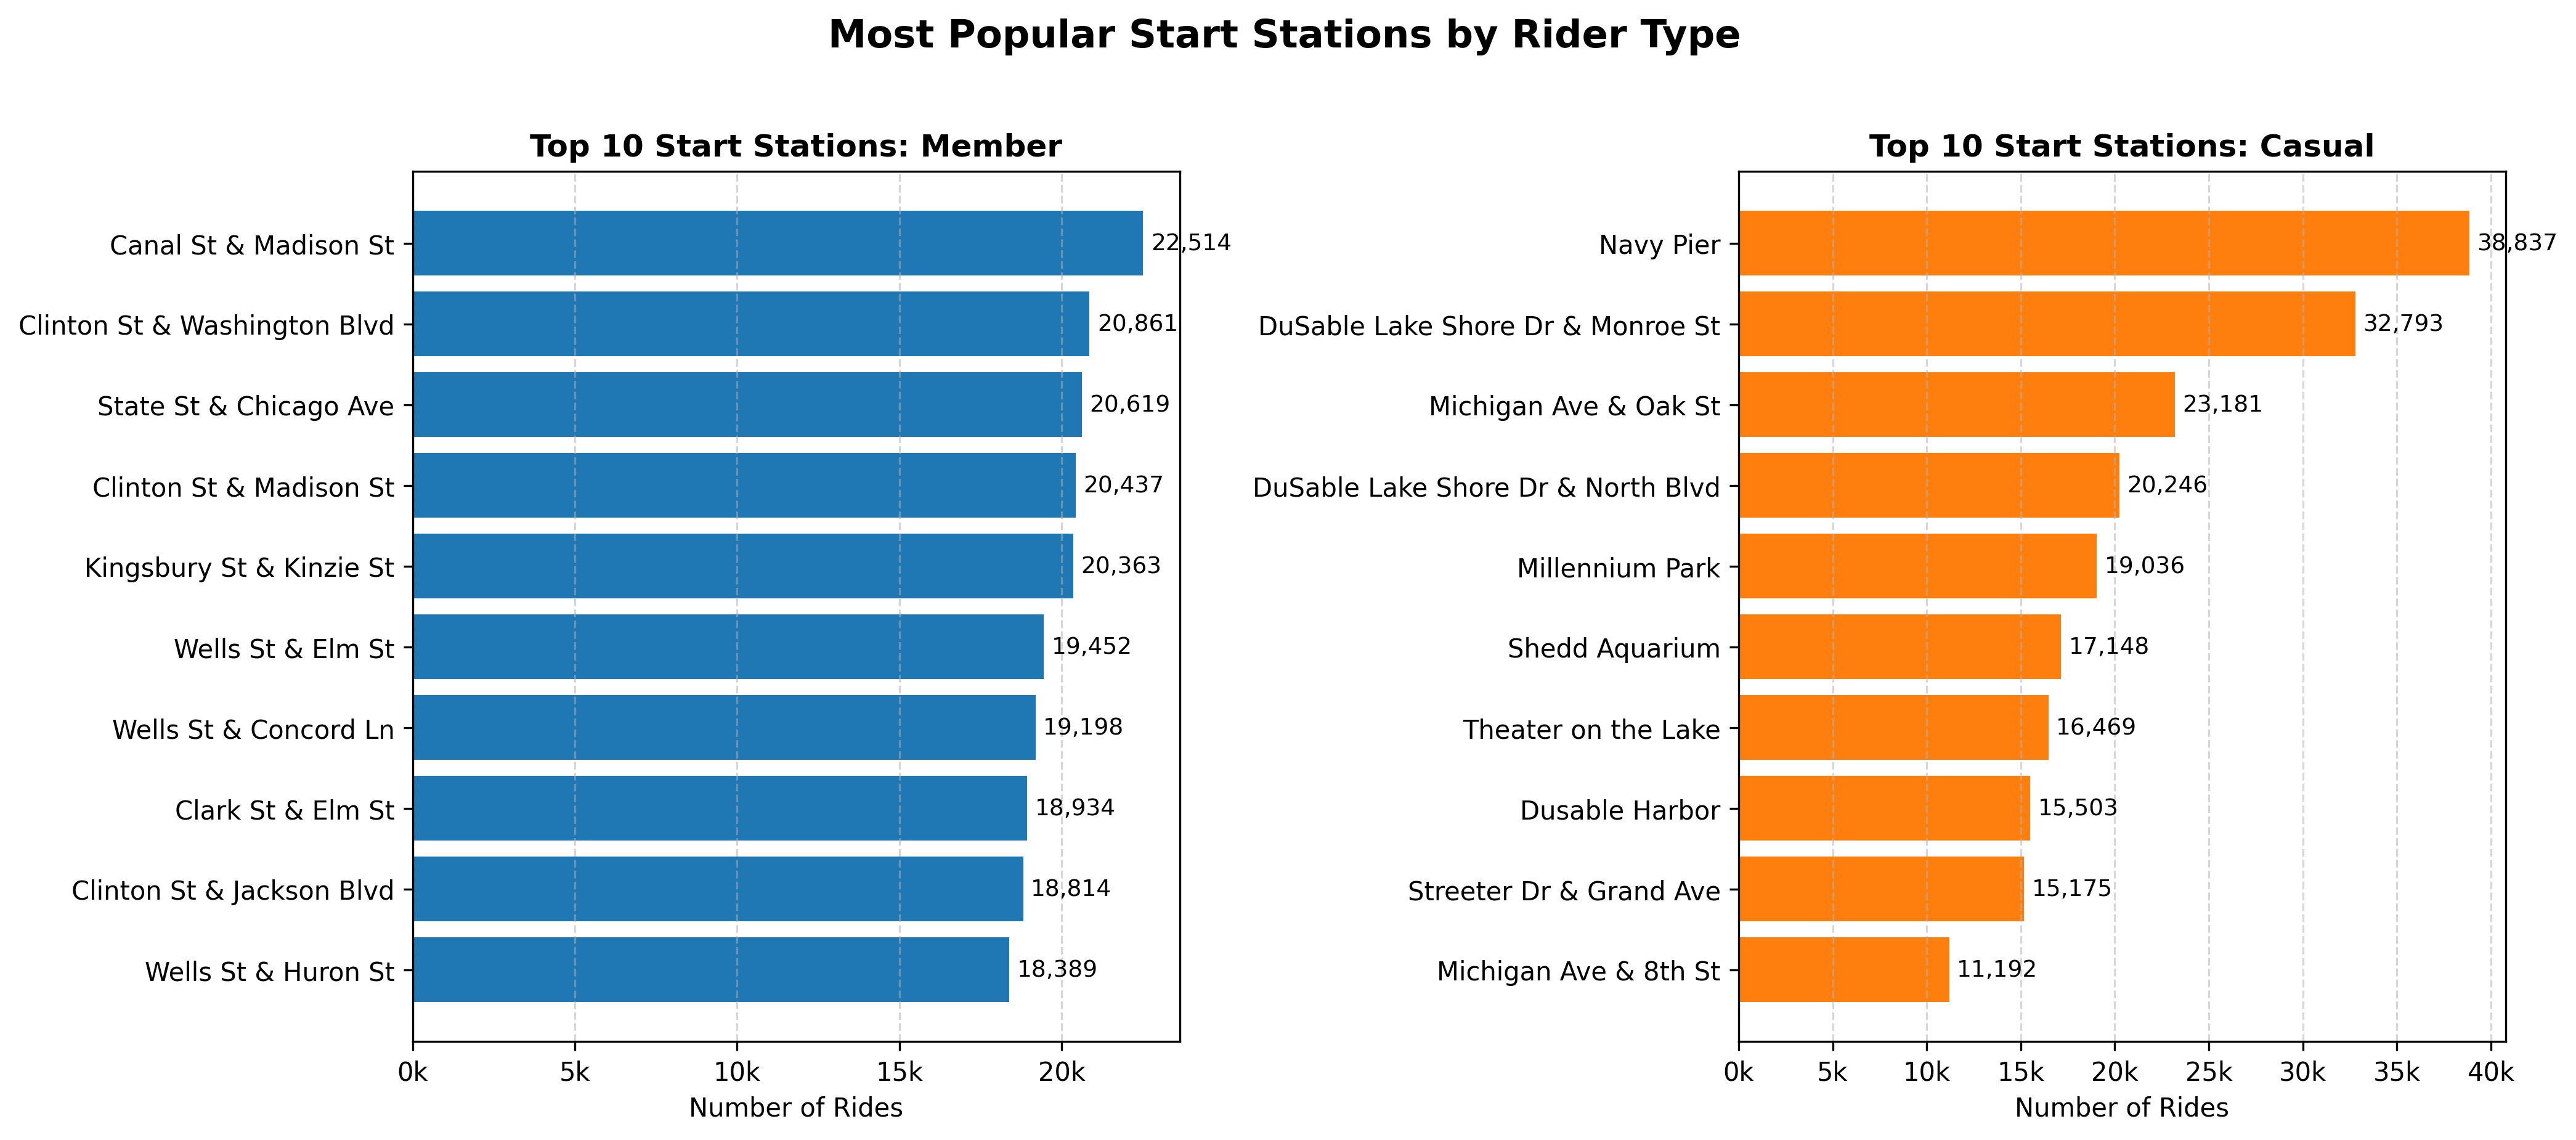

In [79]:
# Prepare top 10 station dataset
top10_member = (
    df[df["member_casual"] == "member"]
    .groupby("start_station_name")
    .size()
    .reset_index(name="ride_count")
    .sort_values("ride_count", ascending=True)
    .tail(10)
)

top10_casual = (
    df[df["member_casual"] == "casual"]
    .groupby("start_station_name")
    .size()
    .reset_index(name="ride_count")
    .sort_values("ride_count", ascending=True)
    .tail(10)
)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=300)

# Left Chart: Member
bars1 = axes[0].barh(
    top10_member["start_station_name"],
    top10_member["ride_count"],
    color="#1f77b4",
)
axes[0].set_title("Top 10 Start Stations: Member", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Number of Rides", fontsize=10)
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

# Add labels
axes[0].bar_label(bars1, fmt="{:,.0f}", padding=3, fontsize=9)

axes[0].xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{int(x/1000)}k")
)

# Right Chart: Casual
bars2 = axes[1].barh(
    top10_casual["start_station_name"],
    top10_casual["ride_count"],
    color="#ff7f0e",
)
axes[1].set_title("Top 10 Start Stations: Casual", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Number of Rides", fontsize=10)
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

# Add labels
axes[1].bar_label(bars2, fmt="{:,.0f}", padding=3, fontsize=9)
axes[1].xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{int(x/1000)}k")
)

fig.suptitle(
    "Most Popular Start Stations by Rider Type",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

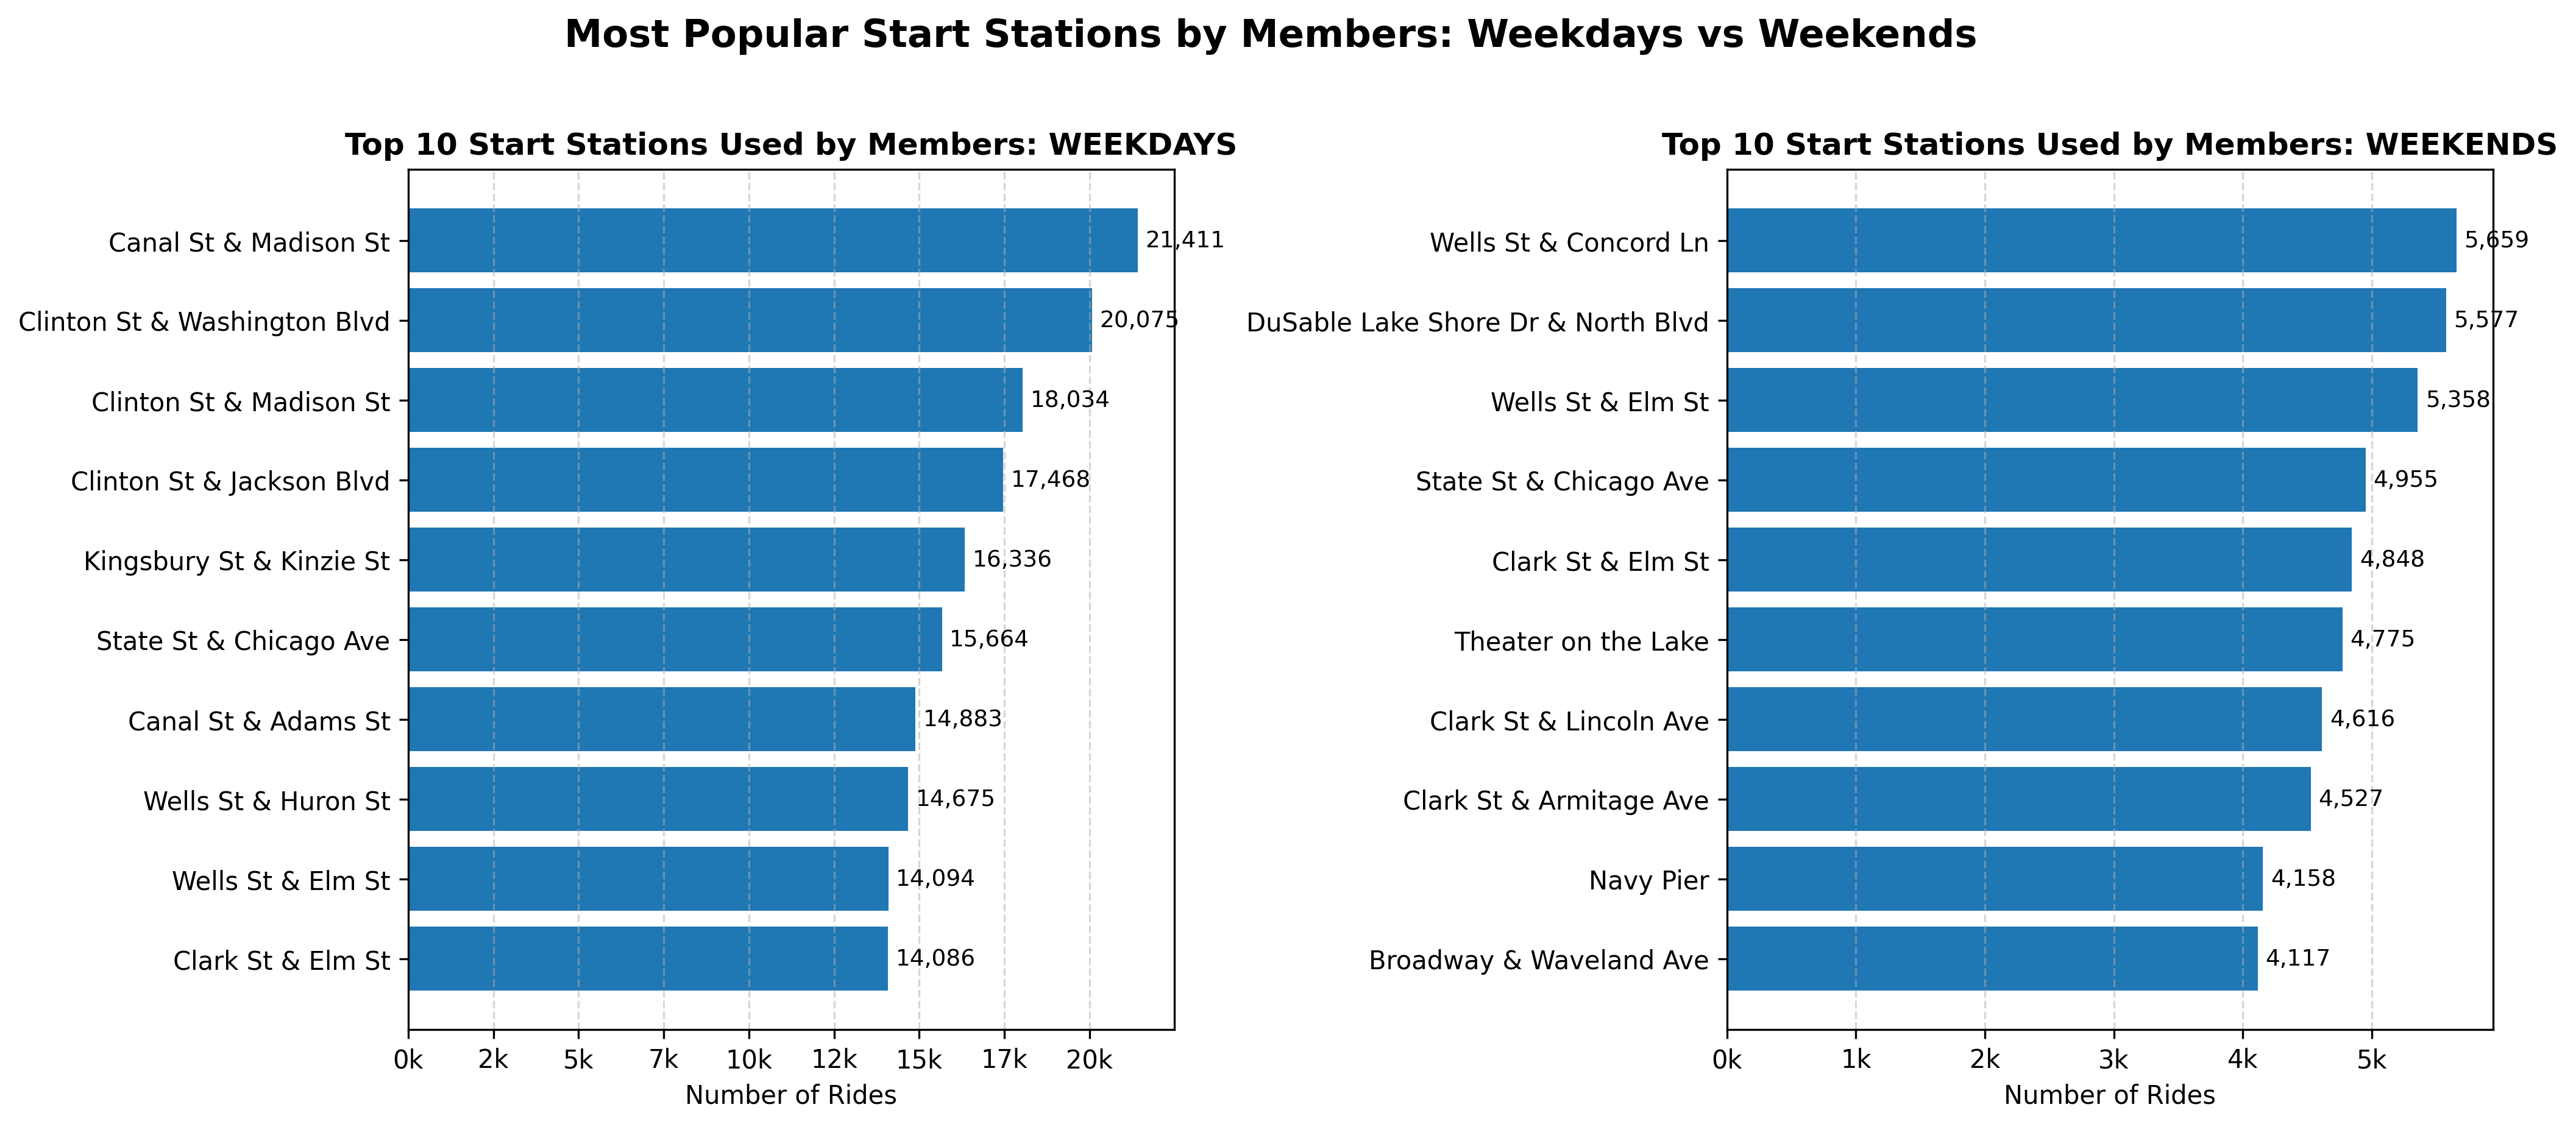

In [80]:
# Prepare top 10 stations dataset
top10_member_weekday = (
    df[(df["member_casual"] == "member") & (df["is_weekend"] == False)]
    .groupby("start_station_name")
    .size()
    .reset_index(name="ride_count")
    .sort_values("ride_count", ascending=True)
    .tail(10)
)

top10_member_weekend = (
    df[(df["member_casual"] == "member") & (df["is_weekend"] == True)]
    .groupby("start_station_name")
    .size()
    .reset_index(name="ride_count")
    .sort_values("ride_count", ascending=True)
    .tail(10)
)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=300)

# Left Chart: Member weekday
bars1 = axes[0].barh(
    top10_member_weekday["start_station_name"],
    top10_member_weekday["ride_count"],
    color="#1f77b4",
)
axes[0].set_title("Top 10 Start Stations Used by Members: WEEKDAYS", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Number of Rides", fontsize=10)
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

axes[0].bar_label(bars1, fmt="{:,.0f}", padding=3, fontsize=9)

axes[0].xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{int(x/1000)}k")
)

# Right Chart: Member weekend
bars2 = axes[1].barh(
    top10_member_weekend["start_station_name"],
    top10_member_weekend["ride_count"],
    color="#1f77b4",
)
axes[1].set_title("Top 10 Start Stations Used by Members: WEEKENDS", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Number of Rides", fontsize=10)
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

axes[1].bar_label(bars2, fmt="{:,.0f}", padding=3, fontsize=9)
axes[1].xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{int(x/1000)}k")
)

fig.suptitle(
    "Most Popular Start Stations by Members: Weekdays vs Weekends",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

In [81]:
top10_member_weekend

,start_station_name,ride_count
97,Broadway & Waveland Ave,4117
800,Navy Pier,4158
198,Clark St & Armitage Ave,4527
213,Clark St & Lincoln Ave,4616
1417,Theater on the Lake,4775
205,Clark St & Elm St,4848
1389,State St & Chicago Ave,4955
1484,Wells St & Elm St,5358
332,DuSable Lake Shore Dr & North Blvd,5577
1483,Wells St & Concord Ln,5659


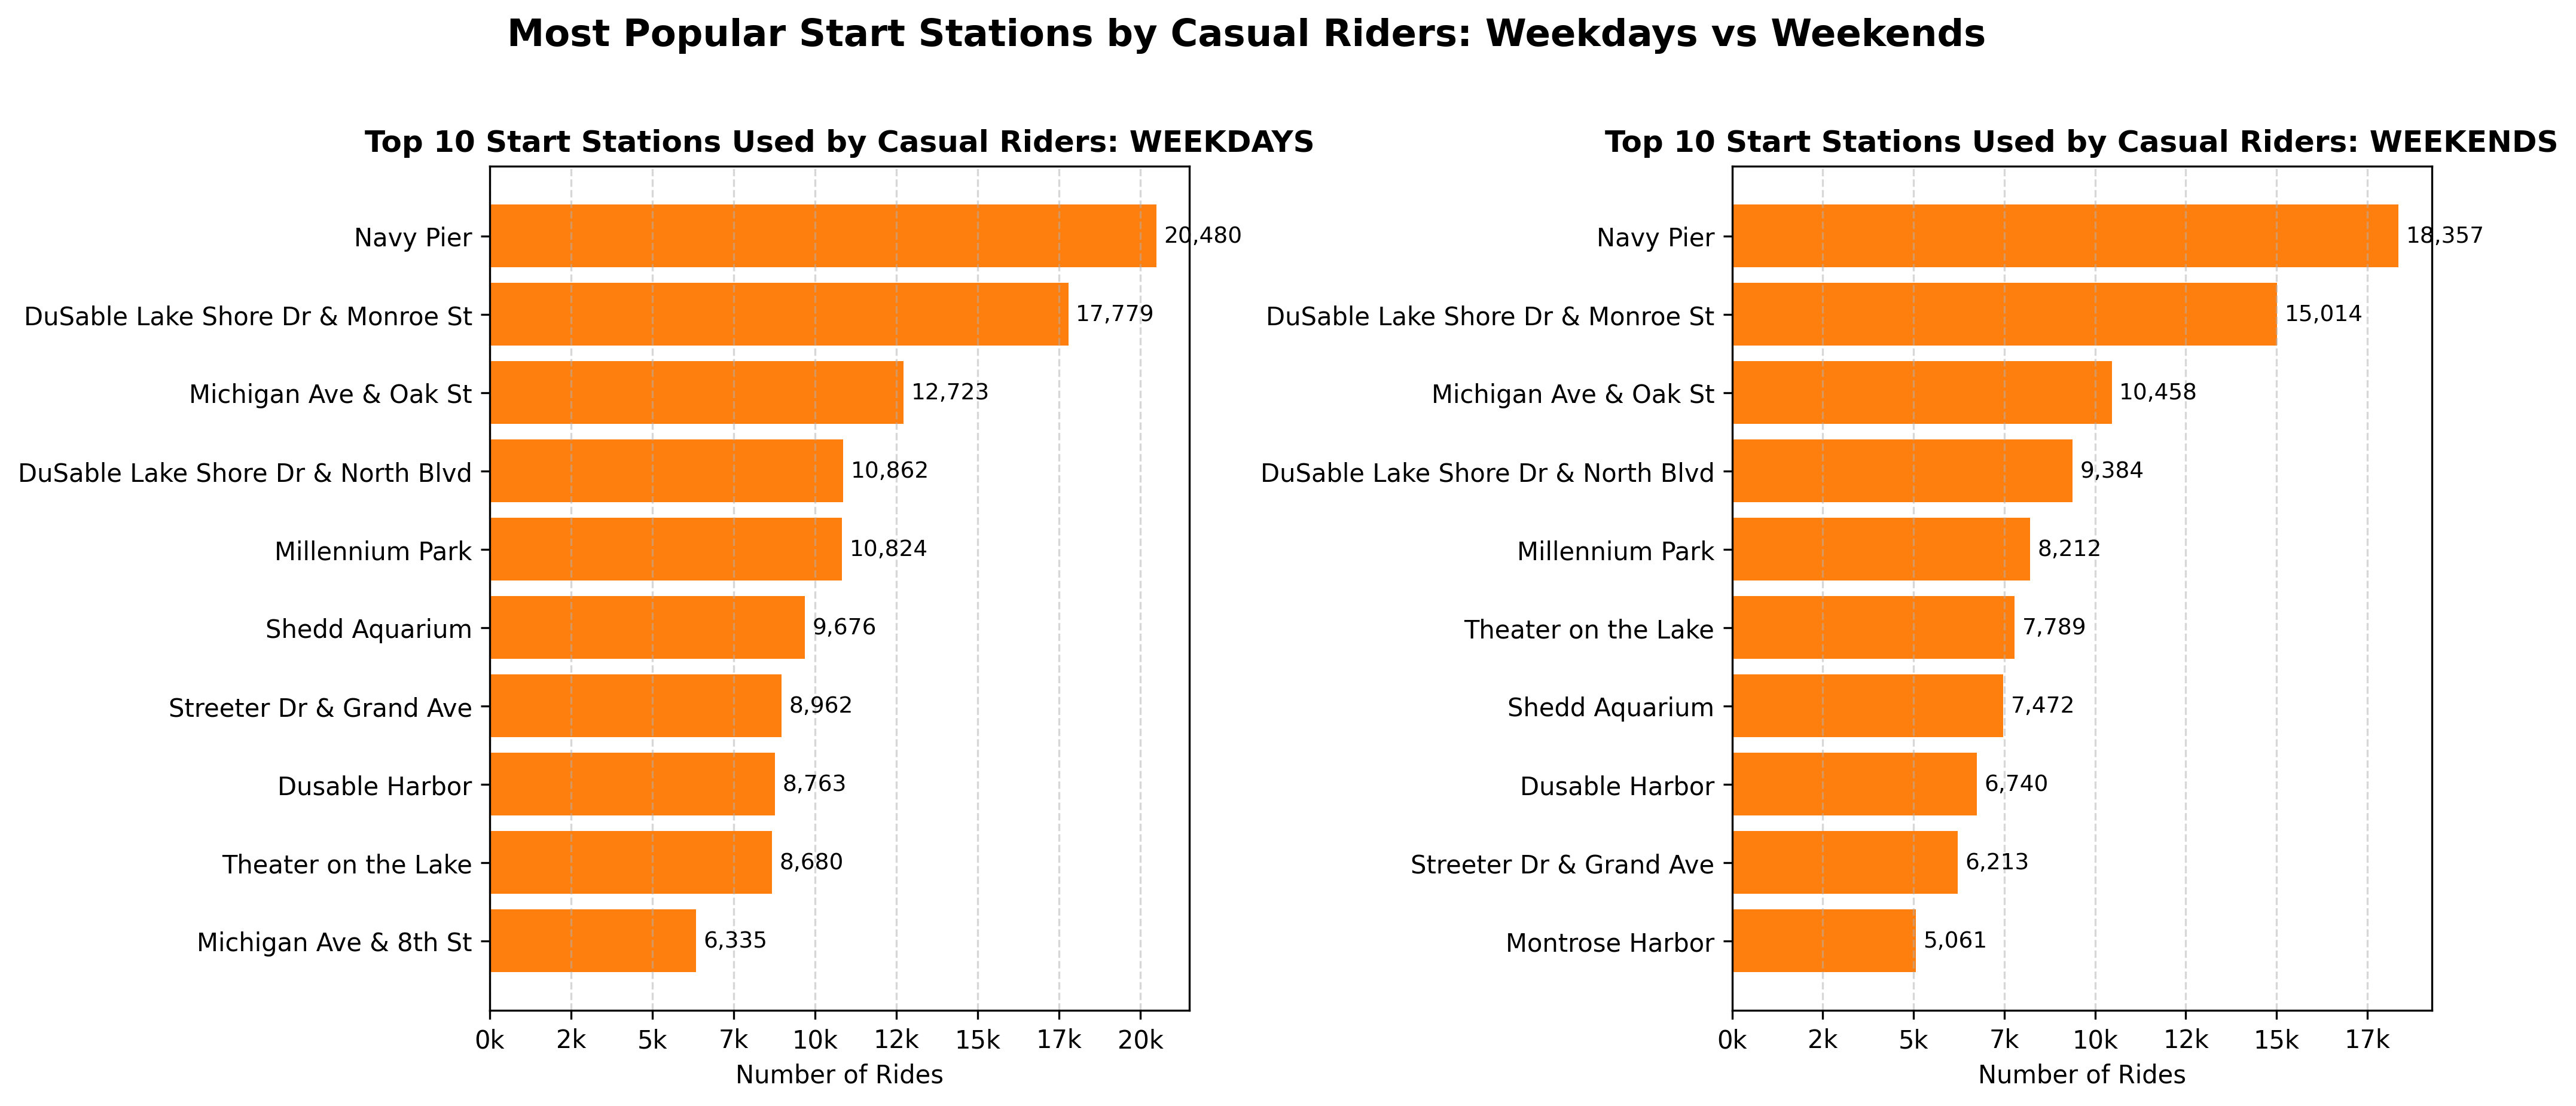

In [82]:
# Prepare top 10 stations dataset
top10_casual_weekday = (
    df[(df["member_casual"] == "casual") & (df["is_weekend"] == False)]
    .groupby("start_station_name")
    .size()
    .reset_index(name="ride_count")
    .sort_values("ride_count", ascending=True)
    .tail(10)
)

top10_casual_weekend = (
    df[(df["member_casual"] == "casual") & (df["is_weekend"] == True)]
    .groupby("start_station_name")
    .size()
    .reset_index(name="ride_count")
    .sort_values("ride_count", ascending=True)
    .tail(10)
)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=300)

# Left Chart: Casual weekday
bars1 = axes[0].barh(
    top10_casual_weekday["start_station_name"],
    top10_casual_weekday["ride_count"],
    color="#ff7f0e",
)
axes[0].set_title("Top 10 Start Stations Used by Casual Riders: WEEKDAYS", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Number of Rides", fontsize=10)
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

axes[0].bar_label(bars1, fmt="{:,.0f}", padding=3, fontsize=9)

axes[0].xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{int(x/1000)}k")
)

# Right Chart: Casual weekend
bars2 = axes[1].barh(
    top10_casual_weekend["start_station_name"],
    top10_casual_weekend["ride_count"],
    color="#ff7f0e",
)
axes[1].set_title("Top 10 Start Stations Used by Casual Riders: WEEKENDS", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Number of Rides", fontsize=10)
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

axes[1].bar_label(bars2, fmt="{:,.0f}", padding=3, fontsize=9)
axes[1].xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{int(x/1000)}k")
)

fig.suptitle(
    "Most Popular Start Stations by Casual Riders: Weekdays vs Weekends",
    fontsize=15,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()